<a href="https://colab.research.google.com/github/suhanidar16/APS360/blob/main/eldersafe_APS360_final.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import os
import zipfile
import shutil
from pathlib import Path

# Mount Drive if not already mounted
from google.colab import drive
drive.mount('/content/drive')

DRIVE_RAW_DIR = Path("/content/drive/MyDrive/eldersafe/data/raw")
LOCAL_EXTRACT_BASE = Path("/content/local_raw")

# Updated dictionary to use 'fallen.zip'
dataset_zips = {
    "standing": DRIVE_RAW_DIR / "standing.zip",
    "sitting": DRIVE_RAW_DIR / "sitting.zip",
    "lying_in_bed": DRIVE_RAW_DIR / "lying_in_bed.zip",
    "fallen": DRIVE_RAW_DIR / "fallen.zip"
}

print("Extracting datasets to local runtime scratch space...")
for name, zip_path in dataset_zips.items():
    if not zip_path.exists():
        print(f"Error: Missing zip file for {name} at {zip_path}")
        continue

    target_dir = LOCAL_EXTRACT_BASE / name
    if target_dir.exists():
        shutil.rmtree(target_dir)
    target_dir.mkdir(parents=True, exist_ok=True)

    print(f"Unpacking {zip_path.name}...")
    with zipfile.ZipFile(zip_path, 'r') as zip_ref:
        zip_ref.extractall(target_dir)

print("Extraction loop complete.")

Mounted at /content/drive
Extracting datasets to local runtime scratch space...
Unpacking standing.zip...
Unpacking sitting.zip...
Unpacking lying_in_bed.zip...
Unpacking fallen.zip...
Extraction loop complete.


In [2]:
import os
import pandas as pd
from pathlib import Path

image_extensions = {'.jpg', '.jpeg', '.png', '.bmp', '.webp'}

# Explicit class mapping for ElderSafe AI
class_mapping = {
    "standing": 0,
    "sitting": 1,
    "lying_in_bed": 2,
    "fallen": 3
}

all_records = []

print("Building master catalog from local folders...")
for folder_name, class_idx in class_mapping.items():
    target_folder = LOCAL_EXTRACT_BASE / folder_name
    if not target_folder.exists():
        print(f"Warning: Folder {target_folder} missing.")
        continue

    class_images = [
        p for p in target_folder.rglob("*")
        if p.is_file() and p.suffix.lower() in image_extensions
    ]

    print(f"  Class {class_idx} ({folder_name}): Found {len(class_images)} images.")

    for img_path in class_images:
        all_records.append({
            "raw_filepath": str(img_path),
            "filename": img_path.name,
            "source_dataset": folder_name,
            "label": class_idx
        })

df_raw_master = pd.DataFrame(all_records)
print(f"\nTotal indexed samples across all 4 sources: {len(df_raw_master)}")

Building master catalog from local folders...
  Class 0 (standing): Found 204 images.
  Class 1 (sitting): Found 400 images.
  Class 2 (lying_in_bed): Found 144 images.
  Class 3 (fallen): Found 474 images.

Total indexed samples across all 4 sources: 1222


In [3]:
from sklearn.model_selection import train_test_split

random_seed = 42

# 70% Train, 30% Temporary split
df_train, df_temp = train_test_split(
    df_raw_master,
    test_size=0.30,
    random_state=random_seed,
    stratify=df_raw_master["label"]
)

# Split remaining 30% evenly into Validation and Test (15% each)
df_val, df_test = train_test_split(
    df_temp,
    test_size=0.50,
    random_state=random_seed,
    stratify=df_temp["label"]
)

df_train = df_train.copy()
df_train["split"] = "train"

df_val = df_val.copy()
df_val["split"] = "val"

df_test = df_test.copy()
df_test["split"] = "test"

df_split_master = pd.concat([df_train, df_val, df_test]).reset_index(drop=True)
print("Stratified distribution grouping finished.")
print(pd.crosstab(df_split_master["source_dataset"], df_split_master["split"]))

Stratified distribution grouping finished.
split           test  train  val
source_dataset                  
fallen            72    331   71
lying_in_bed      21    101   22
sitting           60    280   60
standing          31    143   30


In [4]:
from PIL import Image
from pathlib import Path

drive_clean_dir = Path("/content/drive/MyDrive/eldersafe/data/cleaned")
drive_clean_dir.mkdir(parents=True, exist_ok=True)

final_manifest_records = []
error_count = 0

print("Processing images and writing to Google Drive storage...")
for idx, row in df_split_master.iterrows():
    raw_path = row["raw_filepath"]
    src_name = row["source_dataset"]
    split_group = row["split"]
    lbl = row["label"]

    target_filename = f"elder_{src_name}_{split_group}_{idx:05d}.jpg"
    target_destination = drive_clean_dir / target_filename

    try:
        with Image.open(raw_path) as img:
            img_rgb = img.convert("RGB")
            img_resized = img_rgb.resize((224, 224), Image.Resampling.LANCZOS)
            img_resized.save(target_destination, "JPEG")

            final_manifest_records.append({
                "cleaned_filepath": str(target_destination),
                "filename": target_filename,
                "source_dataset": src_name,
                "label": lbl,
                "split": split_group
            })
    except Exception:
        error_count += 1
        continue

df_final_manifest = pd.DataFrame(final_manifest_records)
df_final_manifest.to_csv(drive_clean_dir / "master_manifest.csv", index=False)

print("\nPipeline execution complete.")
print(f"Successfully processed and saved: {len(df_final_manifest)} images")
print(f"Skipped damaged files: {error_count}")

print("\nYour Progress Report Table Data:")
print(pd.crosstab(df_final_manifest["label"], df_final_manifest["split"]))

Processing images and writing to Google Drive storage...

Pipeline execution complete.
Successfully processed and saved: 1222 images
Skipped damaged files: 0

Your Progress Report Table Data:
split  test  train  val
label                  
0        31    143   30
1        60    280   60
2        21    101   22
3        72    331   71


In [5]:
import pandas as pd
import torch
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from PIL import Image

class ElderSafeDataset(Dataset):
    def __init__(self, manifest_path, split_name, transform=None):
        # Load the master manifest we generated in the previous step
        df = pd.read_csv(manifest_path)
        # Filter rows to match the specific split (train, val, or test)
        self.data = df[df["split"] == split_name].reset_index(drop=True)
        self.transform = transform

    def __len__(self):
        return len(self.data)

    def __getitem__(self, idx):
        row = self.data.iloc[idx]
        img_path = row["cleaned_filepath"]
        label = int(row["label"])

        # Load the image and ensure it is strictly RGB
        image = Image.open(img_path).convert("RGB")

        if self.transform:
            image = self.transform(image)

        return image, label

# Define basic normalization transforms for the ANN baseline
# Resizing to 64x64 to keep the fully connected input size reasonable
base_transforms = transforms.Compose([
    transforms.Resize((64, 64)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

manifest_file = "/content/drive/MyDrive/eldersafe/data/cleaned/master_manifest.csv"

# Instantiate train, validation, and test datasets
train_dataset = ElderSafeDataset(manifest_file, "train", transform=base_transforms)
val_dataset = ElderSafeDataset(manifest_file, "val", transform=base_transforms)
test_dataset = ElderSafeDataset(manifest_file, "test", transform=base_transforms)

# Set up DataLoaders with a standard course batch size of 32
# Shuffle is True only for training to maximize generalization
train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True, drop_last=False)
val_loader = DataLoader(val_dataset, batch_size=32, shuffle=False)
test_loader = DataLoader(test_dataset, batch_size=32, shuffle=False)

print(f"DataLoaders successfully initialized:")
print(f"  Train batches: {len(train_loader)} ({len(train_dataset)} images)")
print(f"  Val batches:   {len(val_loader)} ({len(val_dataset)} images)")
print(f"  Test batches:  {len(test_loader)} ({len(test_dataset)} images)")

DataLoaders successfully initialized:
  Train batches: 27 (855 images)
  Val batches:   6 (183 images)
  Test batches:  6 (184 images)


In [6]:
import torch.nn as nn

class ElderSafeANN(nn.Module):
    def __init__(self, input_dim=3*64*64, num_classes=4):
        super(ElderSafeANN, self).__init__()

        self.pipeline = nn.Sequential(
            # Flatten the 3D image tensor into a 1D vector
            nn.Flatten(),

            # Hidden Layer 1
            nn.Linear(input_dim, 256),
            nn.ReLU(),
            nn.Dropout(p=0.3), # Regularization to control overfitting

            # Hidden Layer 2
            nn.Linear(256, 64),
            nn.ReLU(),

            # Output Layer (Returns 4 logits)
            nn.Linear(64, num_classes)
        )

    def forward(self, x):
        return self.pipeline(x)

# Initialize model and check device configuration
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model_ann = ElderSafeANN().to(device)
print(f"ANN Baseline Model loaded onto: {device}")

ANN Baseline Model loaded onto: cpu


In [7]:
import torch.optim as optim
import numpy as np

criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model_ann.parameters(), lr=0.001)

num_epochs = 20
best_val_loss = float('inf')
checkpoint_path = "/content/drive/MyDrive/eldersafe/models/ann_baseline_best.pt"
os.makedirs(os.path.dirname(checkpoint_path), exist_ok=True)

# Arrays to store history for progress report learning curves
history = {"train_loss": [], "train_acc": [], "val_loss": [], "val_acc": []}

for epoch in range(num_epochs):
    # --- TRAINING PHASE ---
    model_ann.train()
    train_loss, train_correct, train_total = 0.0, 0, 0

    for images, labels in train_loader:
        images, labels = images.to(device), labels.to(device)

        optimizer.zero_grad()
        outputs = model_ann(images)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        train_loss += loss.item() * images.size(0)
        _, predicted = torch.max(outputs, 1)
        train_total += labels.size(0)
        train_correct += (predicted == labels).sum().item()

    epoch_train_loss = train_loss / train_total
    epoch_train_acc = (train_correct / train_total) * 100

    # --- VALIDATION PHASE ---
    model_ann.eval()
    val_loss, val_correct, val_total = 0.0, 0, 0

    with torch.no_grad():
        for images, labels in val_loader:
            images, labels = images.to(device), labels.to(device)
            outputs = model_ann(images)
            loss = criterion(outputs, labels)

            val_loss += loss.item() * images.size(0)
            _, predicted = torch.max(outputs, 1)
            val_total += labels.size(0)
            val_correct += (predicted == labels).sum().item()

    epoch_val_loss = val_loss / val_total
    epoch_val_acc = (val_correct / val_total) * 100

    # Record history logs
    history["train_loss"].append(epoch_train_loss)
    history["train_acc"].append(epoch_train_acc)
    history["val_loss"].append(epoch_val_loss)
    history["val_acc"].append(epoch_val_acc)

    print(f"Epoch [{epoch+1:02d}/{num_epochs}] "
          f"Train Loss: {epoch_train_loss:.4f} | Train Acc: {epoch_train_acc:.2f}% | "
          f"Val Loss: {epoch_val_loss:.4f} | Val Acc: {epoch_val_acc:.2f}%")

    # Save checkpoint if validation performance improves
    if epoch_val_loss < best_val_loss:
        best_val_loss = epoch_val_loss
        torch.save(model_ann.state_dict(), checkpoint_path)
        print(f" Validation loss decreased. Saved checkpoint to Drive.")

print("\nTraining completed successfully.")

Epoch [01/20] Train Loss: 1.1995 | Train Acc: 64.09% | Val Loss: 0.9508 | Val Acc: 73.22%
 Validation loss decreased. Saved checkpoint to Drive.
Epoch [02/20] Train Loss: 0.6442 | Train Acc: 78.48% | Val Loss: 0.4298 | Val Acc: 83.06%
 Validation loss decreased. Saved checkpoint to Drive.
Epoch [03/20] Train Loss: 0.4433 | Train Acc: 82.34% | Val Loss: 0.3685 | Val Acc: 88.52%
 Validation loss decreased. Saved checkpoint to Drive.
Epoch [04/20] Train Loss: 0.3874 | Train Acc: 86.78% | Val Loss: 0.3230 | Val Acc: 87.98%
 Validation loss decreased. Saved checkpoint to Drive.
Epoch [05/20] Train Loss: 0.2723 | Train Acc: 90.41% | Val Loss: 0.2662 | Val Acc: 92.90%
 Validation loss decreased. Saved checkpoint to Drive.
Epoch [06/20] Train Loss: 0.2007 | Train Acc: 92.16% | Val Loss: 0.3214 | Val Acc: 89.62%
Epoch [07/20] Train Loss: 0.2223 | Train Acc: 91.58% | Val Loss: 0.2848 | Val Acc: 90.71%
Epoch [08/20] Train Loss: 0.1870 | Train Acc: 93.22% | Val Loss: 0.2866 | Val Acc: 91.26%
Epoch

In [8]:
import torch
import numpy as np
from sklearn.metrics import classification_report, confusion_matrix, f1_score

# Load the absolute best saved model weights from your training run
checkpoint_path = "/content/drive/MyDrive/eldersafe/models/ann_baseline_best.pt"
model_ann.load_state_dict(torch.load(checkpoint_path, map_location=device))
model_ann.eval()

all_preds = []
all_labels = []

# Disable gradient tracking for pure inference evaluation
with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)
        outputs = model_ann(images)

        _, predicted = torch.max(outputs, 1)

        all_preds.extend(predicted.cpu().numpy())
        all_labels.extend(labels.numpy())

all_preds = np.array(all_preds)
all_labels = np.array(all_labels)

# Calculate key performance metrics
test_accuracy = (all_preds == all_labels).sum() / len(all_labels) * 100
macro_f1 = f1_score(all_labels, all_preds, average='macro')

print("--- ANN BASELINE TEST EVALUATION ---")
print(f"Overall Test Accuracy: {test_accuracy:.2f}%")
print(f"Macro F1-Score:        {macro_f1:.4f}\n")

# Print the per-class metrics (Precision, Recall, F1)
class_names = ["Standing", "Sitting", "Lying in Bed", "Fallen"]
print(classification_report(all_labels, all_preds, target_names=class_names))

--- ANN BASELINE TEST EVALUATION ---
Overall Test Accuracy: 86.41%
Macro F1-Score:        0.8654

              precision    recall  f1-score   support

    Standing       0.91      0.94      0.92        31
     Sitting       0.83      0.90      0.86        60
Lying in Bed       0.76      0.90      0.83        21
      Fallen       0.92      0.79      0.85        72

    accuracy                           0.86       184
   macro avg       0.85      0.88      0.87       184
weighted avg       0.87      0.86      0.86       184



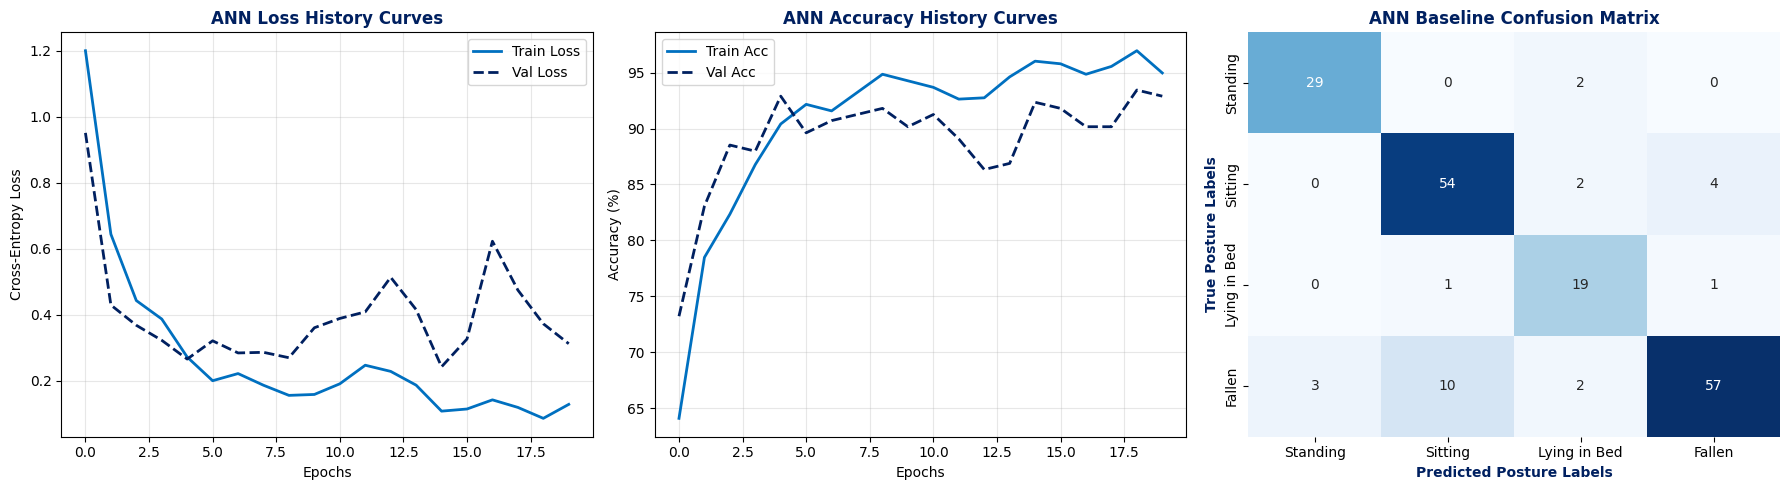

In [9]:
import matplotlib.pyplot as plt
import seaborn as sns

# Set up a clean, professional dual-plot canvas using your blue theme guidelines
fig, axs = plt.subplots(1, 3, figsize=(18, 5))

# 1. Plot Loss History Curve
axs[0].plot(history["train_loss"], label="Train Loss", color='#0070C0', lw=2)
axs[0].plot(history["val_loss"], label="Val Loss", color='#002060', lw=2, linestyle='--')
axs[0].set_title("ANN Loss History Curves", weight='bold', color='#002060')
axs[0].set_xlabel("Epochs")
axs[0].set_ylabel("Cross-Entropy Loss")
axs[0].legend()
axs[0].grid(True, alpha=0.3)

# 2. Plot Accuracy History Curve
axs[1].plot(history["train_acc"], label="Train Acc", color='#0070C0', lw=2)
axs[1].plot(history["val_acc"], label="Val Acc", color='#002060', lw=2, linestyle='--')
axs[1].set_title("ANN Accuracy History Curves", weight='bold', color='#002060')
axs[1].set_xlabel("Epochs")
axs[1].set_ylabel("Accuracy (%)")
axs[1].legend()
axs[1].grid(True, alpha=0.3)

# 3. Compute and Plot the Confusion Matrix
cm = confusion_matrix(all_labels, all_preds)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=class_names, yticklabels=class_names, ax=axs[2], cbar=False)
axs[2].set_title("ANN Baseline Confusion Matrix", weight='bold', color='#002060')
axs[2].set_xlabel("Predicted Posture Labels", weight='bold', color='#002060')
axs[2].set_ylabel("True Posture Labels", weight='bold', color='#002060')

plt.tight_layout()
plt.show()

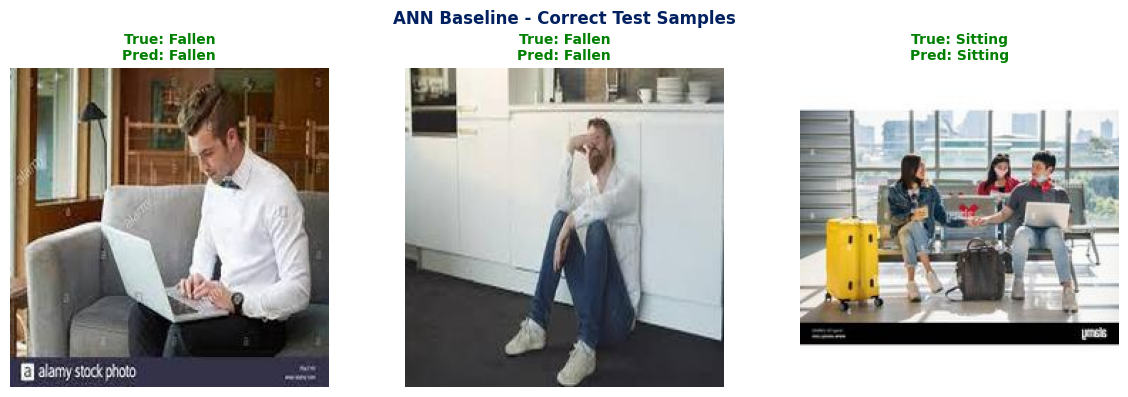

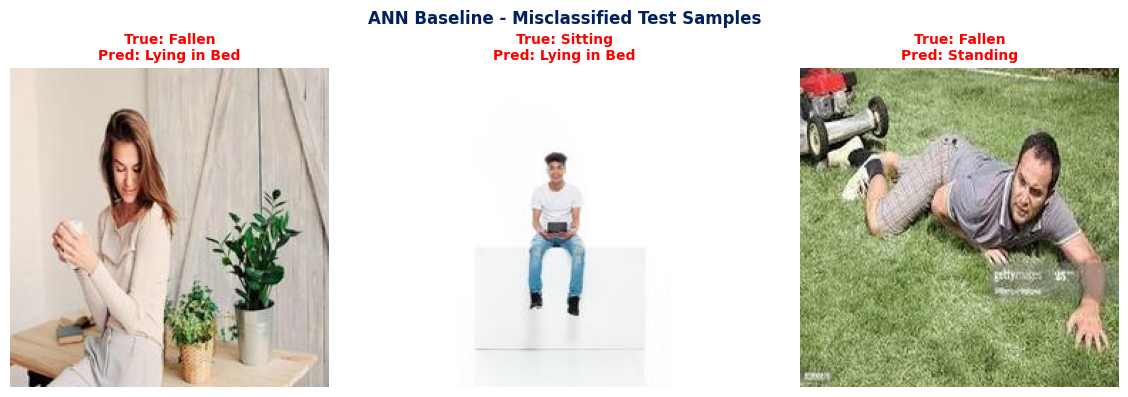

In [10]:
# Create lists to track successful and failed model outcomes
correct_indices = np.where(all_preds == all_labels)[0]
incorrect_indices = np.where(all_preds != all_labels)[0]

def display_samples(indices_list, title_text, max_samples=3):
    plt.figure(figsize=(12, 4))
    samples_to_show = min(max_samples, len(indices_list))

    for i in range(samples_to_show):
        idx = indices_list[i]

        # Access raw image directly from test dataset to avoid dealing with inverse normalization math
        img_path = test_dataset.data.iloc[idx]["cleaned_filepath"]
        img = Image.open(img_path)

        plt.subplot(1, max_samples, i + 1)
        plt.imshow(img)
        plt.title(f"True: {class_names[all_labels[idx]]}\nPred: {class_names[all_preds[idx]]}",
                  fontsize=10,
                  color='green' if all_preds[idx] == all_labels[idx] else 'red',
                  weight='bold')
        plt.axis("off")

    plt.suptitle(title_text, fontsize=12, weight='bold', color='#002060')
    plt.tight_layout()
    plt.show()

# Display examples
display_samples(correct_indices, "ANN Baseline - Correct Test Samples")
display_samples(incorrect_indices, "ANN Baseline - Misclassified Test Samples")

In [11]:
import pandas as pd
import torch
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from PIL import Image

class ElderSafeDataset(Dataset):
    def __init__(self, manifest_path, split_name, transform=None):
        df = pd.read_csv(manifest_path)
        self.data = df[df["split"] == split_name].reset_index(drop=True)
        self.transform = transform

    def __len__(self):
        return len(self.data)

    def __getitem__(self, idx):
        row = self.data.iloc[idx]
        image = Image.open(row["cleaned_filepath"]).convert("RGB")
        label = int(row["label"])

        if self.transform:
            image = self.transform(image)

        return image, label

# Standard ImageNet normalization constraints
norm_mean = [0.485, 0.456, 0.406]
norm_std = [0.229, 0.224, 0.225]

# Training transformations to fight the overfitting seen in your ANN curves
train_transforms = transforms.Compose([
    transforms.Resize((128, 128)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(degrees=10),
    transforms.ToTensor(),
    transforms.Normalize(mean=norm_mean, std=norm_std)
])

# Eval transforms (No random alterations allowed here)
eval_transforms = transforms.Compose([
    transforms.Resize((128, 128)),
    transforms.ToTensor(),
    transforms.Normalize(mean=norm_mean, std=norm_std)
])

manifest_file = "/content/drive/MyDrive/eldersafe/data/cleaned/master_manifest.csv"

train_dataset = ElderSafeDataset(manifest_file, "train", transform=train_transforms)
val_dataset = ElderSafeDataset(manifest_file, "val", transform=eval_transforms)
test_dataset = ElderSafeDataset(manifest_file, "test", transform=eval_transforms)

train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=32, shuffle=False)
test_loader = DataLoader(test_dataset, batch_size=32, shuffle=False)

print(f"CNN DataLoaders Ready. Training samples: {len(train_dataset)}")

CNN DataLoaders Ready. Training samples: 855


In [12]:
import torch.nn as nn

class ElderSafeCNN(nn.Module):
    def __init__(self, num_classes=4):
        super(ElderSafeCNN, self).__init__()

        self.features = nn.Sequential(
            # Block 1: Input 3x128x128 -> Output 16x64x64
            nn.Conv2d(3, 16, kernel_size=3, padding=1),
            nn.BatchNorm2d(16),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2, stride=2),

            # Block 2: Input 16x64x64 -> Output 32x32x32
            nn.Conv2d(16, 32, kernel_size=3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2, stride=2),

            # Block 3: Input 32x32x32 -> Output 64x16x16
            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2, stride=2),

            # Block 4: Input 64x16x16 -> Output 128x8x8
            nn.Conv2d(64, 128, kernel_size=3, padding=1),
            nn.BatchNorm2d(128),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2, stride=2)
        )

        # Adaptive pooling forces the spatial shape to 1x1 regardless of input size
        self.global_pool = nn.AdaptiveAvgPool2d((1, 1))

        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Dropout(p=0.4), # Stronger dropout regularizer to beat background memorization
            nn.Linear(128, 64),
            nn.ReLU(),
            nn.Linear(64, num_classes)
        )

    def forward(self, x):
        x = self.features(x)
        x = self.global_pool(x)
        x = self.classifier(x)
        return x

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model_cnn = ElderSafeCNN().to(device)

# Compute parameter count for your rubric documentation
total_params = sum(p.numel() for p in model_cnn.parameters() if p.requires_grad)
print(f"CNN Model loaded onto {device}. Trainable Parameters: {total_params:,}")

CNN Model loaded onto cpu. Trainable Parameters: 106,436


In [13]:
import torch.optim as optim

criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model_cnn.parameters(), lr=0.001, weight_decay=1e-4)

num_epochs = 20
best_loss = float('inf')
cnn_save_path = "/content/drive/MyDrive/eldersafe/models/cnn_primary_best.pt"

cnn_history = {"train_loss": [], "train_acc": [], "val_loss": [], "val_acc": []}

print("Starting Primary CNN Training Pipeline...")
for epoch in range(num_epochs):
    # Training Loop
    model_cnn.train()
    t_loss, t_correct, t_total = 0.0, 0, 0
    for imgs, labels in train_loader:
        imgs, labels = imgs.to(device), labels.to(device)

        optimizer.zero_grad()
        outputs = model_cnn(imgs)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        t_loss += loss.item() * imgs.size(0)
        _, preds = torch.max(outputs, 1)
        t_total += labels.size(0)
        t_correct += (preds == labels).sum().item()

    epoch_t_loss = t_loss / t_total
    epoch_t_acc = (t_correct / t_total) * 100

    # Validation Loop
    model_cnn.eval()
    v_loss, v_correct, v_total = 0.0, 0, 0
    with torch.no_grad():
        for imgs, labels in val_loader:
            imgs, labels = imgs.to(device), labels.to(device)
            outputs = model_cnn(imgs)
            loss = criterion(outputs, labels)

            v_loss += loss.item() * imgs.size(0)
            _, preds = torch.max(outputs, 1)
            v_total += labels.size(0)
            v_correct += (preds == labels).sum().item()

    epoch_v_loss = v_loss / v_total
    epoch_v_acc = (v_correct / v_total) * 100

    cnn_history["train_loss"].append(epoch_t_loss)
    cnn_history["train_acc"].append(epoch_t_acc)
    cnn_history["val_loss"].append(epoch_v_loss)
    cnn_history["val_acc"].append(epoch_v_acc)

    print(f"Epoch [{epoch+1:02d}/{num_epochs}] Train Loss: {epoch_t_loss:.4f} Acc: {epoch_t_acc:.2f}% | Val Loss: {epoch_v_loss:.4f} Acc: {epoch_v_acc:.2f}%")

    if epoch_v_loss < best_loss:
        best_loss = epoch_v_loss
        torch.save(model_cnn.state_dict(), cnn_save_path)
        print("Saved new optimal CNN weights to Drive.")

print("\nCNN Training Phase Finalized.")

Starting Primary CNN Training Pipeline...
Epoch [01/20] Train Loss: 1.0361 Acc: 57.31% | Val Loss: 0.9591 Acc: 60.11%
Saved new optimal CNN weights to Drive.
Epoch [02/20] Train Loss: 0.7704 Acc: 70.41% | Val Loss: 0.6712 Acc: 74.86%
Saved new optimal CNN weights to Drive.
Epoch [03/20] Train Loss: 0.6978 Acc: 73.22% | Val Loss: 0.6063 Acc: 79.78%
Saved new optimal CNN weights to Drive.
Epoch [04/20] Train Loss: 0.5943 Acc: 78.95% | Val Loss: 0.5015 Acc: 81.97%
Saved new optimal CNN weights to Drive.
Epoch [05/20] Train Loss: 0.5590 Acc: 78.95% | Val Loss: 0.6182 Acc: 78.14%
Epoch [06/20] Train Loss: 0.5665 Acc: 80.47% | Val Loss: 0.6635 Acc: 73.77%
Epoch [07/20] Train Loss: 0.5346 Acc: 79.65% | Val Loss: 0.5155 Acc: 81.97%
Epoch [08/20] Train Loss: 0.5035 Acc: 82.57% | Val Loss: 0.4561 Acc: 83.06%
Saved new optimal CNN weights to Drive.
Epoch [09/20] Train Loss: 0.4773 Acc: 82.34% | Val Loss: 0.4713 Acc: 83.61%
Epoch [10/20] Train Loss: 0.4282 Acc: 84.21% | Val Loss: 0.5984 Acc: 75.41

In [14]:
import torch
import numpy as np
from sklearn.metrics import classification_report, confusion_matrix, f1_score

# Load the best weights saved during training
cnn_save_path = "/content/drive/MyDrive/eldersafe/models/cnn_primary_best.pt"
model_cnn.load_state_dict(torch.load(cnn_save_path, map_location=device))
model_cnn.eval()

cnn_preds = []
cnn_labels = []

# No gradients needed for evaluation
with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)
        outputs = model_cnn(images)

        _, predicted = torch.max(outputs, 1)

        cnn_preds.extend(predicted.cpu().numpy())
        cnn_labels.extend(labels.numpy())

cnn_preds = np.array(cnn_preds)
cnn_labels = np.array(cnn_labels)

# Calculate final test metrics
cnn_test_acc = (cnn_preds == cnn_labels).sum() / len(cnn_labels) * 100
cnn_macro_f1 = f1_score(cnn_labels, cnn_preds, average='macro')

print("Primary CNN Model Test Evaluation")
print(f"Overall Test Accuracy: {cnn_test_acc:.2f}%")
print(f"Macro F1-Score:        {cnn_macro_f1:.4f}\n")

class_names = ["Standing", "Sitting", "Lying in Bed", "Fallen"]
print(classification_report(cnn_labels, cnn_preds, target_names=class_names))

Primary CNN Model Test Evaluation
Overall Test Accuracy: 89.13%
Macro F1-Score:        0.8697

              precision    recall  f1-score   support

    Standing       0.94      0.97      0.95        31
     Sitting       0.93      0.92      0.92        60
Lying in Bed       0.87      0.62      0.72        21
      Fallen       0.85      0.92      0.88        72

    accuracy                           0.89       184
   macro avg       0.90      0.86      0.87       184
weighted avg       0.89      0.89      0.89       184



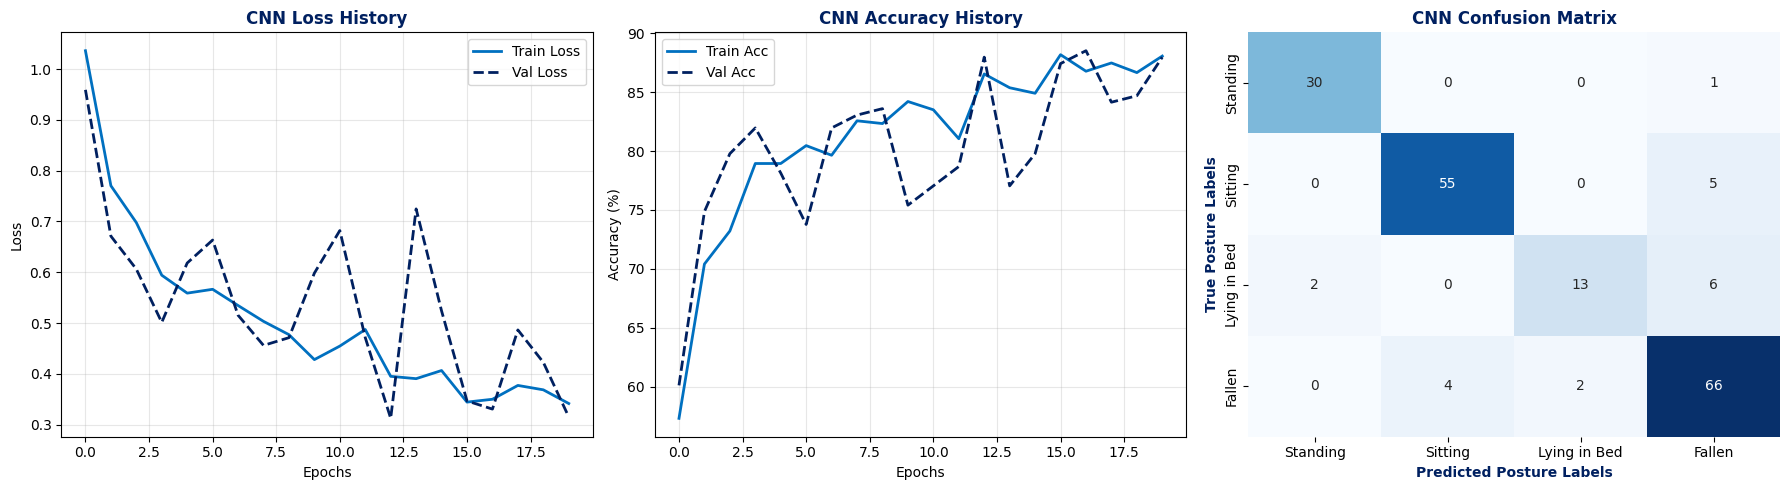

In [15]:
import matplotlib.pyplot as plt
import seaborn as sns

fig, axs = plt.subplots(1, 3, figsize=(18, 5))

# 1. CNN Loss Curve
axs[0].plot(cnn_history["train_loss"], label="Train Loss", color='#0070C0', lw=2)
axs[0].plot(cnn_history["val_loss"], label="Val Loss", color='#002060', lw=2, linestyle='--')
axs[0].set_title("CNN Loss History", weight='bold', color='#002060')
axs[0].set_xlabel("Epochs")
axs[0].set_ylabel("Loss")
axs[0].legend()
axs[0].grid(True, alpha=0.3)

# 2. CNN Accuracy Curve
axs[1].plot(cnn_history["train_acc"], label="Train Acc", color='#0070C0', lw=2)
axs[1].plot(cnn_history["val_acc"], label="Val Acc", color='#002060', lw=2, linestyle='--')
axs[1].set_title("CNN Accuracy History", weight='bold', color='#002060')
axs[1].set_xlabel("Epochs")
axs[1].set_ylabel("Accuracy (%)")
axs[1].legend()
axs[1].grid(True, alpha=0.3)

# 3. CNN Confusion Matrix
cnn_cm = confusion_matrix(cnn_labels, cnn_preds)
sns.heatmap(cnn_cm, annot=True, fmt='d', cmap='Blues', xticklabels=class_names, yticklabels=class_names, ax=axs[2], cbar=False)
axs[2].set_title("CNN Confusion Matrix", weight='bold', color='#002060')
axs[2].set_xlabel("Predicted Posture Labels", weight='bold', color='#002060')
axs[2].set_ylabel("True Posture Labels", weight='bold', color='#002060')

plt.tight_layout()
plt.show()

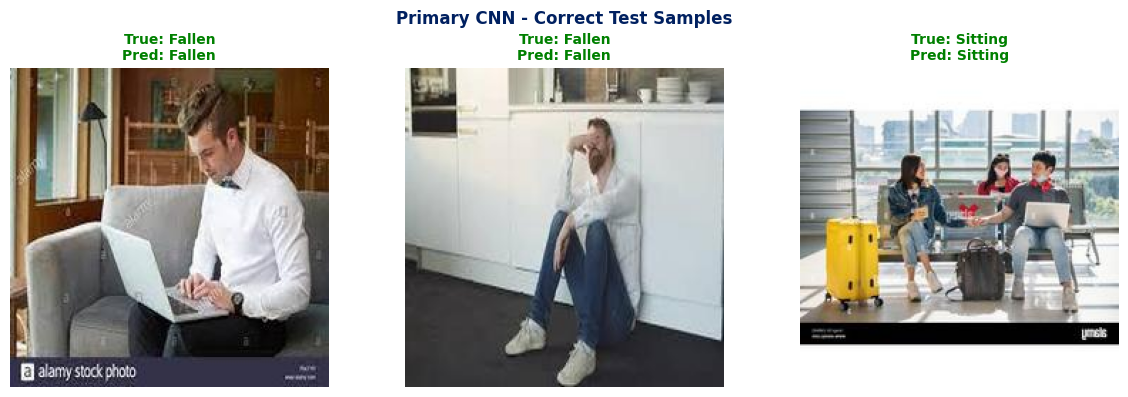

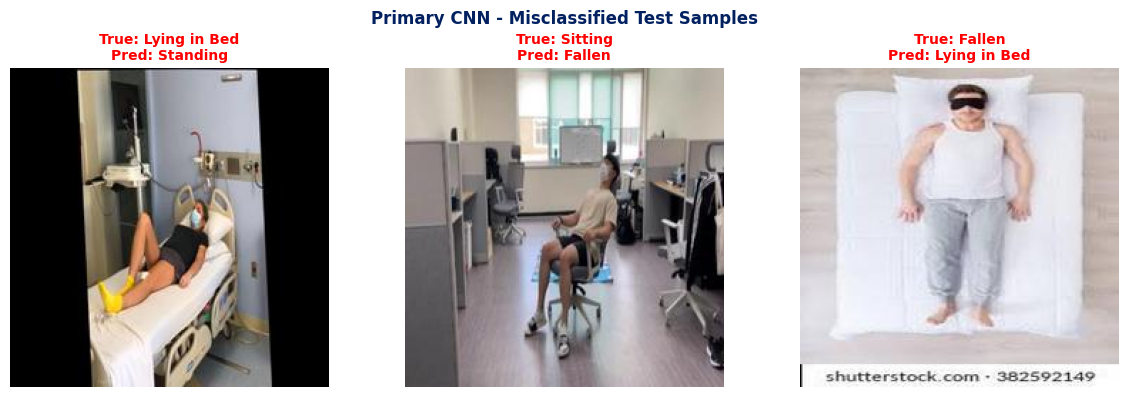

In [16]:
cnn_correct_idx = np.where(cnn_preds == cnn_labels)[0]
cnn_incorrect_idx = np.where(cnn_preds != cnn_labels)[0]

def display_cnn_samples(indices_list, title_text, max_samples=3):
    plt.figure(figsize=(12, 4))
    samples_to_show = min(max_samples, len(indices_list))

    for i in range(samples_to_show):
        idx = indices_list[i]
        img_path = test_dataset.data.iloc[idx]["cleaned_filepath"]
        img = Image.open(img_path)

        plt.subplot(1, max_samples, i + 1)
        plt.imshow(img)
        plt.title(f"True: {class_names[cnn_labels[idx]]}\nPred: {class_names[cnn_preds[idx]]}",
                  fontsize=10,
                  color='green' if cnn_preds[idx] == cnn_labels[idx] else 'red',
                  weight='bold')
        plt.axis("off")

    plt.suptitle(title_text, fontsize=12, weight='bold', color='#002060')
    plt.tight_layout()
    plt.show()

# Run the display functions
display_cnn_samples(cnn_correct_idx, "Primary CNN - Correct Test Samples")
display_cnn_samples(cnn_incorrect_idx, "Primary CNN - Misclassified Test Samples")

In [17]:
# Save your raw data grid layout
plt.figure(1) # Select the 3x3 raw preview grid figure
plt.savefig('cleaned_grid.png', bbox_inches='tight', dpi=300)

# Save your ANN evaluation plots
plt.figure(2) # Select the ANN history/confusion matrix figure
plt.savefig('ann_metrics.png', bbox_inches='tight', dpi=300)

# Save your CNN evaluation plots
plt.figure(3) # Select the CNN history/confusion matrix figure
plt.savefig('cnn_metrics.png', bbox_inches='tight', dpi=300)

<Figure size 640x480 with 0 Axes>

<Figure size 640x480 with 0 Axes>

<Figure size 640x480 with 0 Axes>

# Final Stage: Rigorous Experiments, Transfer Learning, and Safety Analysis

Everything above (data extraction, cleaning, the ANN baseline, and the first custom CNN)
was completed for the progress report. The cells below finish the project:

1. Lock the splits and set all random seeds for reproducibility.
2. Check the dataset for duplicate images, cross-split leakage, and source bias.
3. Do a manual label audit.
4. Add class-weighted loss to help the small *Lying in Bed* class and the safety-critical *Fallen* class.
5. Retrain an improved custom CNN with a proper training loop (early stopping + LR scheduling).
6. Add a pretrained **ResNet18** transfer-learning model (frozen head, then fine-tune `layer4`).
7. Evaluate every model on the test set **once**, with per-class and fall-specific metrics.
8. Tune a fall-alert probability threshold, add Grad-CAM, and run simple robustness tests.


## Step 1 — Reproducibility and frozen splits

In [18]:
import os
import random
import numpy as np
import pandas as pd
import torch

def set_seed(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

set_seed(42)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)

# The manifest built during the progress report is our single source of truth.
# Every model below reads its images from this exact file so the comparison is fair.
manifest_file = "/content/drive/MyDrive/eldersafe/data/cleaned/master_manifest.csv"
manifest = pd.read_csv(manifest_file)

class_names = ["Standing", "Sitting", "Lying in Bed", "Fallen"]
FALL_CLASS = 3  # "Fallen" == lying on the floor == the safety-critical class

# Save the split assignments to disk so they can never drift.
split_dir = "/content/drive/MyDrive/eldersafe/data/splits"
os.makedirs(split_dir, exist_ok=True)
for split_name in ["train", "val", "test"]:
    manifest[manifest["split"] == split_name].to_csv(
        os.path.join(split_dir, f"{split_name}_split.csv"), index=False)

print("Saved frozen split files to", split_dir)
print(pd.crosstab(manifest["label"], manifest["split"]))


Using device: cpu
Saved frozen split files to /content/drive/MyDrive/eldersafe/data/splits
split  test  train  val
label                  
0        31    143   30
1        60    280   60
2        21    101   22
3        72    331   71


## Step 2 — Dataset integrity: duplicates, leakage, and source bias

Because the four classes were downloaded from different public posture datasets, the two
biggest risks are (a) identical or near-identical images landing in more than one split, which
would make the test scores look better than they really are, and (b) each class coming from a
single source so the model could cheat by recognizing the dataset instead of the posture.

In [19]:
import hashlib

def md5_hash(path):
    with open(path, "rb") as f:
        return hashlib.md5(f.read()).hexdigest()

manifest["file_hash"] = manifest["cleaned_filepath"].apply(md5_hash)

# Exact duplicates (identical bytes)
n_exact_dupes = int(manifest.duplicated("file_hash", keep=False).sum())
print("Exact duplicate image rows:", n_exact_dupes)

# Cross-split leakage: same image showing up in more than one split
hash_splits = manifest.groupby("file_hash")["split"].nunique()
print("Identical images spanning multiple splits:", int((hash_splits > 1).sum()))


Exact duplicate image rows: 0
Identical images spanning multiple splits: 0


In [20]:
# Near-duplicates (resized copies, adjacent video frames) via perceptual hashing.
try:
    import imagehash
except ImportError:
    !pip install imagehash -q
    import imagehash
from PIL import Image

def phash(path):
    try:
        return str(imagehash.phash(Image.open(path).convert("RGB")))
    except Exception:
        return None

manifest["phash"] = manifest["cleaned_filepath"].apply(phash)
print("Near-duplicate rows (perceptual hash):",
      int(manifest.duplicated("phash", keep=False).sum()))

phash_splits = manifest.groupby("phash")["split"].nunique()
print("Perceptually-similar images spanning multiple splits:",
      int((phash_splits > 1).sum()))


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 296.7/296.7 kB 14.4 MB/s eta 0:00:00
Near-duplicate rows (perceptual hash): 12
Perceptually-similar images spanning multiple splits: 5


In [21]:
# Source-bias check: which source dataset does each class come from?
source_table = pd.crosstab(manifest["source_dataset"], manifest["label"])
source_table.columns = [class_names[c] for c in source_table.columns]
print(source_table)
print("\nNote: if each class comes almost entirely from one source folder, the model may")
print("learn source-specific backgrounds. This is acknowledged as a limitation in the report.")


                Standing  Sitting  Lying in Bed  Fallen
source_dataset                                         
fallen                 0        0             0     474
lying_in_bed           0        0           144       0
sitting                0      400             0       0
standing             204        0             0       0

Note: if each class comes almost entirely from one source folder, the model may
learn source-specific backgrounds. This is acknowledged as a limitation in the report.


## Step 3 — Manual label audit

A quick visual check that the labels actually match the images (a standing person is standing,
a *Lying in Bed* image really shows a bed, etc.). This lets the report state that the data was
inspected rather than blindly downloaded.

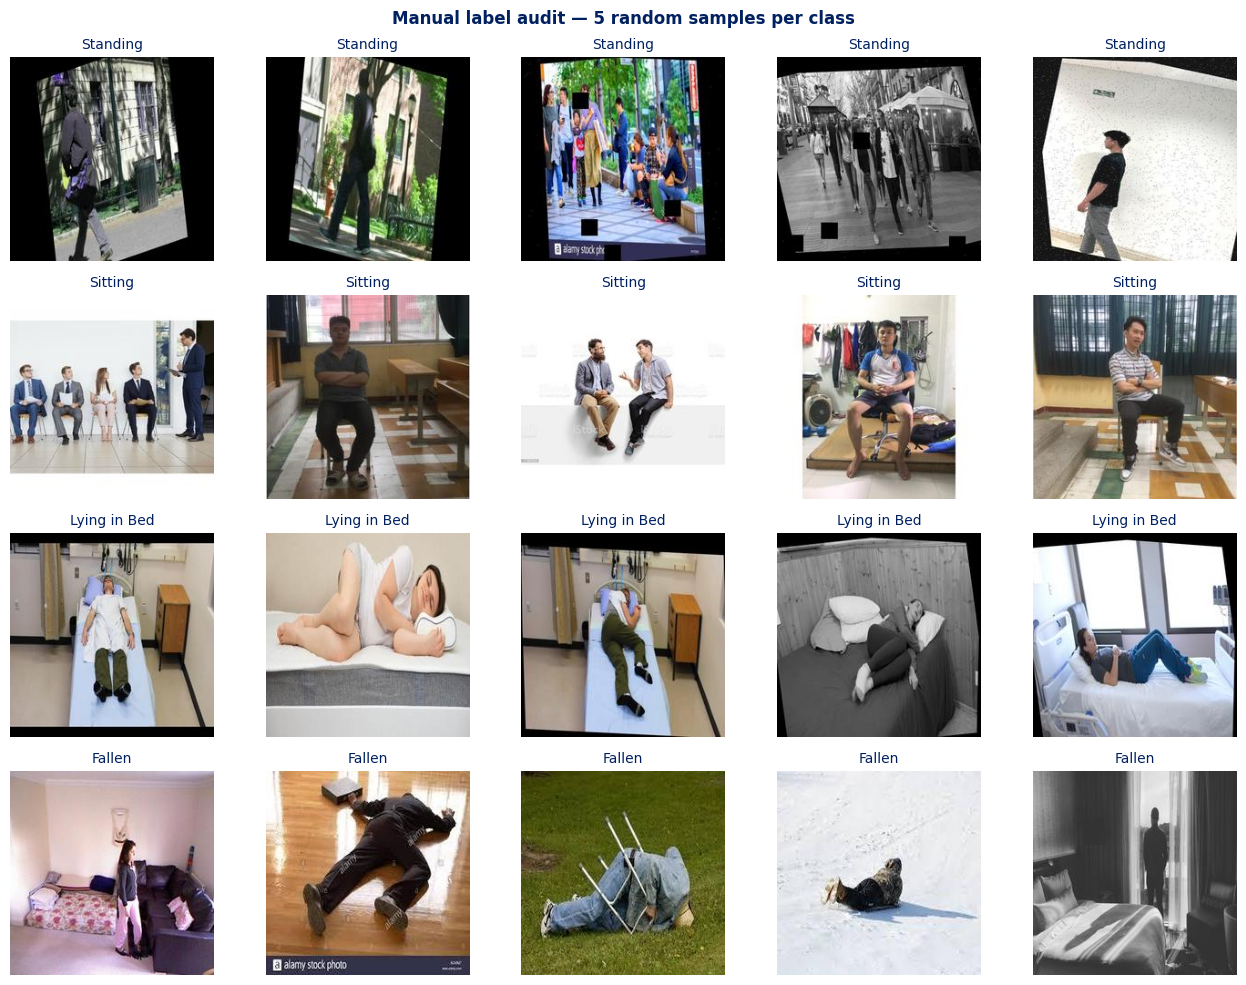

In [22]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(4, 5, figsize=(13, 10))
for c in range(4):
    sample = manifest[manifest["label"] == c].sample(5, random_state=42)
    for j, (_, row) in enumerate(sample.iterrows()):
        axes[c, j].imshow(Image.open(row["cleaned_filepath"]).convert("RGB"))
        axes[c, j].set_title(class_names[c], color="#002060", fontsize=10)
        axes[c, j].axis("off")
plt.suptitle("Manual label audit — 5 random samples per class",
             weight="bold", color="#002060")
plt.tight_layout()
plt.show()



Improved augmentation for the 128x128 CNN, standard 224x224 transforms
for ResNet18, and inverse-frequency class weights so the small classes are not ignored.

In [23]:
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms

norm_mean = [0.485, 0.456, 0.406]
norm_std = [0.229, 0.224, 0.225]

class ElderSafeDataset(Dataset):
    """Reads the images listed in a manifest CSV for one split."""
    def __init__(self, manifest_path, split_name, transform=None):
        df = pd.read_csv(manifest_path)
        self.data = df[df["split"] == split_name].reset_index(drop=True)
        self.transform = transform

    def __len__(self):
        return len(self.data)

    def __getitem__(self, idx):
        row = self.data.iloc[idx]
        image = Image.open(row["cleaned_filepath"]).convert("RGB")
        label = int(row["label"])
        if self.transform:
            image = self.transform(image)
        return image, label

# Custom CNN transforms (128x128). Only mild changes that keep the posture meaningful.
cnn_train_tf = transforms.Compose([
    transforms.Resize((144, 144)),
    transforms.RandomResizedCrop(128, scale=(0.85, 1.0), ratio=(0.9, 1.1)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(10),
    transforms.ColorJitter(brightness=0.15, contrast=0.15, saturation=0.10),
    transforms.ToTensor(),
    transforms.Normalize(norm_mean, norm_std),
])
cnn_eval_tf = transforms.Compose([
    transforms.Resize((128, 128)),
    transforms.ToTensor(),
    transforms.Normalize(norm_mean, norm_std),
])

# ResNet18 transforms (224x224)
tf_train_tf = transforms.Compose([
    transforms.Resize((256, 256)),
    transforms.RandomResizedCrop(224, scale=(0.85, 1.0)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(10),
    transforms.ColorJitter(brightness=0.15, contrast=0.15),
    transforms.ToTensor(),
    transforms.Normalize(norm_mean, norm_std),
])
tf_eval_tf = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(norm_mean, norm_std),
])

def make_loaders(train_tf, eval_tf, batch_size=32):
    train_ds = ElderSafeDataset(manifest_file, "train", transform=train_tf)
    val_ds   = ElderSafeDataset(manifest_file, "val",   transform=eval_tf)
    test_ds  = ElderSafeDataset(manifest_file, "test",  transform=eval_tf)
    return (
        (train_ds, val_ds, test_ds),
        (DataLoader(train_ds, batch_size=batch_size, shuffle=True),
         DataLoader(val_ds,   batch_size=batch_size, shuffle=False),
         DataLoader(test_ds,  batch_size=batch_size, shuffle=False)),
    )

# Inverse-frequency class weights, computed from the real training counts.
train_counts = manifest[manifest["split"] == "train"]["label"].value_counts().sort_index()
train_counts = torch.tensor(train_counts.values, dtype=torch.float32)
class_weights = 1.0 / train_counts
class_weights = class_weights / class_weights.sum() * len(class_weights)
class_weights = class_weights.to(device)
print("Train counts per class:", train_counts.tolist())
print("Class weights:", [round(w, 3) for w in class_weights.cpu().tolist()])


Train counts per class: [143.0, 280.0, 101.0, 331.0]
Class weights: [1.191, 0.608, 1.686, 0.515]


In [24]:
import torch.nn as nn

class ElderSafeCNN(nn.Module):
    """Four conv blocks + adaptive average pooling. Kept small on purpose so it does
    not just memorize the 855 training images."""
    def __init__(self, num_classes=4, dropout=0.4):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(3, 32, 3, padding=1),   nn.BatchNorm2d(32),  nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(32, 64, 3, padding=1),  nn.BatchNorm2d(64),  nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(64, 128, 3, padding=1), nn.BatchNorm2d(128), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(128, 256, 3, padding=1),nn.BatchNorm2d(256), nn.ReLU(), nn.MaxPool2d(2),
        )
        self.pool = nn.AdaptiveAvgPool2d((1, 1))
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Dropout(dropout),
            nn.Linear(256, 64), nn.ReLU(),
            nn.Dropout(dropout * 0.75),
            nn.Linear(64, num_classes),
        )

    def forward(self, x):
        x = self.features(x)
        x = self.pool(x)
        return self.classifier(x)


In [25]:
import copy

def train_model(model, train_loader, val_loader, criterion, optimizer,
                scheduler=None, num_epochs=30, patience=6):
    """Standard train/validate loop with best-checkpoint restoring and early stopping."""
    history = {"train_loss": [], "val_loss": [], "train_acc": [], "val_acc": []}
    best_weights = copy.deepcopy(model.state_dict())
    best_val_loss, best_epoch, stale = float("inf"), 0, 0

    for epoch in range(num_epochs):
        # --- train ---
        model.train()
        run_loss, correct, total = 0.0, 0, 0
        for images, labels in train_loader:
            images, labels = images.to(device), labels.to(device)
            optimizer.zero_grad()
            logits = model(images)
            loss = criterion(logits, labels)
            loss.backward()
            optimizer.step()
            run_loss += loss.item() * images.size(0)
            correct += (logits.argmax(1) == labels).sum().item()
            total += labels.size(0)
        train_loss, train_acc = run_loss / total, correct / total

        # --- validate ---
        model.eval()
        run_loss, correct, total = 0.0, 0, 0
        with torch.no_grad():
            for images, labels in val_loader:
                images, labels = images.to(device), labels.to(device)
                logits = model(images)
                run_loss += criterion(logits, labels).item() * images.size(0)
                correct += (logits.argmax(1) == labels).sum().item()
                total += labels.size(0)
        val_loss, val_acc = run_loss / total, correct / total

        for key, value in zip(history, [train_loss, val_loss, train_acc, val_acc]):
            history[key].append(value)

        if scheduler is not None:
            scheduler.step(val_loss)

        if val_loss < best_val_loss:
            best_val_loss, best_epoch = val_loss, epoch + 1
            best_weights = copy.deepcopy(model.state_dict())
            stale = 0
        else:
            stale += 1

        print(f"Epoch {epoch+1:02d}: train loss={train_loss:.4f} acc={train_acc:.3f} | "
              f"val loss={val_loss:.4f} acc={val_acc:.3f}")

        if stale >= patience:
            print("Early stopping triggered.")
            break

    model.load_state_dict(best_weights)
    print(f"Restored best weights from epoch {best_epoch} (val loss {best_val_loss:.4f}).")
    return model, history, best_epoch, best_val_loss


## Evaluation helpers (used for every model)

In [26]:
from sklearn.metrics import (accuracy_score, f1_score, classification_report,
                             confusion_matrix)

def collect_predictions(model, loader):
    """Return (true labels, predicted labels, softmax probabilities) for a loader."""
    model.eval()
    ys, preds, probs = [], [], []
    with torch.no_grad():
        for images, labels in loader:
            p = torch.softmax(model(images.to(device)), dim=1)
            ys.extend(labels.numpy())
            preds.extend(p.argmax(1).cpu().numpy())
            probs.extend(p.cpu().numpy())
    return np.array(ys), np.array(preds), np.array(probs)

def summarize(name, y_true, y_pred):
    acc = accuracy_score(y_true, y_pred)
    macro = f1_score(y_true, y_pred, average="macro")
    weighted = f1_score(y_true, y_pred, average="weighted")
    print(f"=== {name} ===")
    print(f"Accuracy: {acc*100:.2f}%  |  Macro F1: {macro:.4f}  |  Weighted F1: {weighted:.4f}")
    print(classification_report(y_true, y_pred, target_names=class_names, digits=4))
    return {"accuracy": acc, "macro_f1": macro, "weighted_f1": weighted}

def fall_metrics(y_true, y_pred):
    """Treat the four-class output as a binary fall / no-fall alarm."""
    true_fall = (y_true == FALL_CLASS).astype(int)
    pred_fall = (y_pred == FALL_CLASS).astype(int)
    tn, fp, fn, tp = confusion_matrix(true_fall, pred_fall, labels=[0, 1]).ravel()
    return {
        "fall_recall": tp / (tp + fn) if (tp + fn) else 0.0,
        "fall_precision": tp / (tp + fp) if (tp + fp) else 0.0,
        "false_negative_rate": fn / (fn + tp) if (fn + tp) else 0.0,
        "false_positive_rate": fp / (fp + tn) if (fp + tn) else 0.0,
    }


In [27]:
import torch.optim as optim

(cnn_train_ds, cnn_val_ds, cnn_test_ds), (cnn_train_ld, cnn_val_ld, cnn_test_ld) = \
    make_loaders(cnn_train_tf, cnn_eval_tf, batch_size=32)

experiments = [
    {"name": "CNN-A", "lr": 1e-3, "dropout": 0.4, "weighted": False},
    {"name": "CNN-B", "lr": 1e-3, "dropout": 0.4, "weighted": True},
    {"name": "CNN-C", "lr": 3e-4, "dropout": 0.4, "weighted": True},
]

cnn_runs, cnn_experiment_rows = {}, []

for cfg in experiments:
    print("\n" + "=" * 60)
    print("Training", cfg["name"], cfg)
    set_seed(42)  # identical starting point for a fair comparison
    model = ElderSafeCNN(dropout=cfg["dropout"]).to(device)
    crit = nn.CrossEntropyLoss(weight=class_weights if cfg["weighted"] else None)
    opt = optim.AdamW(model.parameters(), lr=cfg["lr"], weight_decay=1e-4)
    sched = optim.lr_scheduler.ReduceLROnPlateau(opt, mode="min", factor=0.5, patience=2)

    model, hist, best_epoch, best_val_loss = train_model(
        model, cnn_train_ld, cnn_val_ld, crit, opt, sched, num_epochs=30, patience=6)

    y_val, pred_val, _ = collect_predictions(model, cnn_val_ld)
    cnn_runs[cfg["name"]] = {"model": model, "history": hist}
    cnn_experiment_rows.append({
        "model": cfg["name"], "learning_rate": cfg["lr"], "dropout": cfg["dropout"],
        "class_weights": cfg["weighted"], "best_epoch": best_epoch,
        "best_val_loss": round(best_val_loss, 4),
        "val_accuracy": round(accuracy_score(y_val, pred_val), 4),
        "val_macro_f1": round(f1_score(y_val, pred_val, average="macro"), 4),
    })

cnn_experiment_df = pd.DataFrame(cnn_experiment_rows)
print("\nCNN experiment summary (selected on validation, not test):")
print(cnn_experiment_df.to_string(index=False))

best_cnn_name = cnn_experiment_df.sort_values("val_macro_f1", ascending=False).iloc[0]["model"]
best_cnn = cnn_runs[best_cnn_name]["model"]
best_cnn_history = cnn_runs[best_cnn_name]["history"]
print("\nSelected custom CNN configuration:", best_cnn_name)



Training CNN-A {'name': 'CNN-A', 'lr': 0.001, 'dropout': 0.4, 'weighted': False}
Epoch 01: train loss=1.1058 acc=0.499 | val loss=1.0018 acc=0.497
Epoch 02: train loss=0.9165 acc=0.629 | val loss=0.8394 acc=0.678
Epoch 03: train loss=0.8199 acc=0.675 | val loss=1.3077 acc=0.503
Epoch 04: train loss=0.7700 acc=0.701 | val loss=0.8840 acc=0.612
Epoch 05: train loss=0.6652 acc=0.736 | val loss=0.5527 acc=0.770
Epoch 06: train loss=0.6920 acc=0.733 | val loss=0.6633 acc=0.754
Epoch 07: train loss=0.6063 acc=0.775 | val loss=0.5910 acc=0.814
Epoch 08: train loss=0.5488 acc=0.786 | val loss=0.6609 acc=0.754
Epoch 09: train loss=0.5241 acc=0.823 | val loss=0.4716 acc=0.847
Epoch 10: train loss=0.4567 acc=0.830 | val loss=0.4040 acc=0.852
Epoch 11: train loss=0.4513 acc=0.834 | val loss=0.4200 acc=0.842
Epoch 12: train loss=0.4462 acc=0.841 | val loss=0.4093 acc=0.847
Epoch 13: train loss=0.4079 acc=0.854 | val loss=0.3829 acc=0.858
Epoch 14: train loss=0.4262 acc=0.846 | val loss=0.4468 acc=

## Step 9 — Transfer learning with ResNet18

Two stages: first train a fresh classifier head on frozen ImageNet features, then unfreeze the
last residual block (`layer4`) and fine-tune it with a very small learning rate. Transfer
learning is a good fit here because the dataset (855 training images) is small.

In [28]:
from torchvision.models import resnet18, ResNet18_Weights

(tf_train_ds, tf_val_ds, tf_test_ds), (tf_train_ld, tf_val_ld, tf_test_ld) = \
    make_loaders(tf_train_tf, tf_eval_tf, batch_size=32)

set_seed(42)
resnet = resnet18(weights=ResNet18_Weights.DEFAULT)

# Stage 1: freeze the backbone, train only a new head.
for p in resnet.parameters():
    p.requires_grad = False
num_features = resnet.fc.in_features
resnet.fc = nn.Sequential(nn.Dropout(0.4), nn.Linear(num_features, 4))
resnet = resnet.to(device)

crit = nn.CrossEntropyLoss(weight=class_weights)
opt = optim.AdamW(resnet.fc.parameters(), lr=1e-3, weight_decay=1e-4)
sched = optim.lr_scheduler.ReduceLROnPlateau(opt, mode="min", factor=0.5, patience=2)

print("Stage 1 — training the new classification head")
resnet, resnet_hist1, _, _ = train_model(
    resnet, tf_train_ld, tf_val_ld, crit, opt, sched, num_epochs=15, patience=5)


Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 111MB/s]


Stage 1 — training the new classification head
Epoch 01: train loss=1.3278 acc=0.430 | val loss=0.9415 acc=0.710
Epoch 02: train loss=0.9401 acc=0.592 | val loss=0.6852 acc=0.803
Epoch 03: train loss=0.7925 acc=0.705 | val loss=0.5618 acc=0.836
Epoch 04: train loss=0.6297 acc=0.779 | val loss=0.4873 acc=0.869
Epoch 05: train loss=0.6023 acc=0.764 | val loss=0.4400 acc=0.880
Epoch 06: train loss=0.5392 acc=0.787 | val loss=0.3683 acc=0.902
Epoch 07: train loss=0.5013 acc=0.804 | val loss=0.3477 acc=0.907
Epoch 08: train loss=0.5026 acc=0.818 | val loss=0.3281 acc=0.896
Epoch 09: train loss=0.4968 acc=0.807 | val loss=0.2977 acc=0.923
Epoch 10: train loss=0.4513 acc=0.823 | val loss=0.2776 acc=0.923
Epoch 11: train loss=0.4429 acc=0.818 | val loss=0.2734 acc=0.929
Epoch 12: train loss=0.4845 acc=0.808 | val loss=0.2723 acc=0.929
Epoch 13: train loss=0.4088 acc=0.841 | val loss=0.2451 acc=0.945
Epoch 14: train loss=0.3860 acc=0.850 | val loss=0.2379 acc=0.929
Epoch 15: train loss=0.4024 a

In [29]:
# Stage 2: unfreeze the last residual block and fine-tune it gently.
for p in resnet.layer4.parameters():
    p.requires_grad = True

opt = optim.AdamW([
    {"params": resnet.layer4.parameters(), "lr": 1e-5},
    {"params": resnet.fc.parameters(),     "lr": 1e-4},
], weight_decay=1e-4)
sched = optim.lr_scheduler.ReduceLROnPlateau(opt, mode="min", factor=0.5, patience=2)

print("Stage 2 — fine-tuning layer4 + head")
resnet, resnet_hist2, resnet_best_epoch, resnet_best_val = train_model(
    resnet, tf_train_ld, tf_val_ld, crit, opt, sched, num_epochs=15, patience=5)

# One continuous history across both stages for plotting.
resnet_history = {k: resnet_hist1[k] + resnet_hist2[k] for k in resnet_hist1}


Stage 2 — fine-tuning layer4 + head
Epoch 01: train loss=0.3746 acc=0.861 | val loss=0.2022 acc=0.945
Epoch 02: train loss=0.2836 acc=0.901 | val loss=0.1608 acc=0.967
Epoch 03: train loss=0.2464 acc=0.913 | val loss=0.1376 acc=0.967
Epoch 04: train loss=0.2134 acc=0.919 | val loss=0.1189 acc=0.973
Epoch 05: train loss=0.1864 acc=0.929 | val loss=0.1072 acc=0.973
Epoch 06: train loss=0.1694 acc=0.938 | val loss=0.0949 acc=0.973
Epoch 07: train loss=0.1651 acc=0.936 | val loss=0.0869 acc=0.978
Epoch 08: train loss=0.1452 acc=0.938 | val loss=0.0844 acc=0.989
Epoch 09: train loss=0.1165 acc=0.959 | val loss=0.0740 acc=0.989
Epoch 10: train loss=0.1163 acc=0.961 | val loss=0.0707 acc=0.978
Epoch 11: train loss=0.1023 acc=0.956 | val loss=0.0666 acc=0.984
Epoch 12: train loss=0.0977 acc=0.958 | val loss=0.0673 acc=0.989
Epoch 13: train loss=0.0927 acc=0.970 | val loss=0.0586 acc=0.995
Epoch 14: train loss=0.0868 acc=0.968 | val loss=0.0552 acc=0.984
Epoch 15: train loss=0.0882 acc=0.974 | 

In [30]:
# Rebuild the ANN's 64x64 test loader and reload its best checkpoint so it is
# evaluated on exactly the same test images as the other two models.
ann_eval_tf = transforms.Compose([
    transforms.Resize((64, 64)),
    transforms.ToTensor(),
    transforms.Normalize(norm_mean, norm_std),
])
ann_test_ld = DataLoader(
    ElderSafeDataset(manifest_file, "test", transform=ann_eval_tf),
    batch_size=32, shuffle=False)
model_ann.load_state_dict(torch.load(
    "/content/drive/MyDrive/eldersafe/models/ann_baseline_best.pt", map_location=device))

final_models = {
    "ANN": (model_ann, ann_test_ld),
    "Custom CNN": (best_cnn, cnn_test_ld),
    "ResNet18": (resnet, tf_test_ld),
}

test_predictions, final_rows = {}, []
for name, (mdl, loader) in final_models.items():
    y_true, y_pred, y_prob = collect_predictions(mdl, loader)
    test_predictions[name] = (y_true, y_pred, y_prob)
    base = summarize(name, y_true, y_pred)
    fm = fall_metrics(y_true, y_pred)
    final_rows.append({
        "Model": name,
        "Parameters": sum(p.numel() for p in mdl.parameters()),
        "Test Accuracy (%)": round(base["accuracy"] * 100, 2),
        "Macro F1": round(base["macro_f1"], 4),
        "Fall Recall": round(fm["fall_recall"], 4),
        "Fall FNR": round(fm["false_negative_rate"], 4),
        "Fall Precision": round(fm["fall_precision"], 4),
    })

final_table = pd.DataFrame(final_rows)
print("\n================ FINAL MODEL COMPARISON ================")
print(final_table.to_string(index=False))


=== ANN ===
Accuracy: 86.41%  |  Macro F1: 0.8654  |  Weighted F1: 0.8640
              precision    recall  f1-score   support

    Standing     0.9062    0.9355    0.9206        31
     Sitting     0.8308    0.9000    0.8640        60
Lying in Bed     0.7600    0.9048    0.8261        21
      Fallen     0.9194    0.7917    0.8507        72

    accuracy                         0.8641       184
   macro avg     0.8541    0.8830    0.8654       184
weighted avg     0.8701    0.8641    0.8640       184

=== Custom CNN ===
Accuracy: 94.57%  |  Macro F1: 0.9359  |  Weighted F1: 0.9449
              precision    recall  f1-score   support

    Standing     0.9394    1.0000    0.9688        31
     Sitting     0.9508    0.9667    0.9587        60
Lying in Bed     0.9444    0.8095    0.8718        21
      Fallen     0.9444    0.9444    0.9444        72

    accuracy                         0.9457       184
   macro avg     0.9448    0.9302    0.9359       184
weighted avg     0.9457    0.9

## Step 13 — Tuning the fall-alert threshold

The default rule flags a fall only when *Fallen* has the highest probability. For a safety
system we can lower that bar to catch more real falls. The threshold is chosen on the
**validation** set (keeping precision reasonable) and then applied to the test set once.

In [31]:
# Tune on validation using the strongest transfer model (ResNet18).
val_true, _, val_prob = collect_predictions(resnet, tf_val_ld)
val_fall = (val_true == FALL_CLASS).astype(int)

print("threshold   fall_recall   fall_precision")
best_thr, best_score = 0.50, -1.0
for thr in np.arange(0.20, 0.81, 0.05):
    pred = (val_prob[:, FALL_CLASS] >= thr).astype(int)
    tn, fp, fn, tp = confusion_matrix(val_fall, pred, labels=[0, 1]).ravel()
    recall = tp / (tp + fn) if (tp + fn) else 0.0
    precision = tp / (tp + fp) if (tp + fp) else 0.0
    # Favour recall, but penalise precision dropping below 0.80.
    score = recall if precision >= 0.80 else recall - (0.80 - precision)
    if score > best_score:
        best_score, best_thr = score, thr
    print(f"  {thr:.2f}         {recall:.3f}          {precision:.3f}")

print(f"\nChosen fall-alert threshold (from validation): {best_thr:.2f}\n")

# Apply the default and the tuned threshold once to the test set.
test_true, _, test_prob = test_predictions["ResNet18"]
test_fall = (test_true == FALL_CLASS).astype(int)
for label, thr in [("Default 0.50", 0.50), (f"Tuned {best_thr:.2f}", best_thr)]:
    pred = (test_prob[:, FALL_CLASS] >= thr).astype(int)
    tn, fp, fn, tp = confusion_matrix(test_fall, pred, labels=[0, 1]).ravel()
    recall = tp / (tp + fn) if (tp + fn) else 0.0
    precision = tp / (tp + fp) if (tp + fp) else 0.0
    fnr = fn / (fn + tp) if (fn + tp) else 0.0
    print(f"{label}: fall recall={recall:.3f}, precision={precision:.3f}, FNR={fnr:.3f}")


threshold   fall_recall   fall_precision
  0.20         0.986          0.946
  0.25         0.986          0.986
  0.30         0.986          1.000
  0.35         0.986          1.000
  0.40         0.986          1.000
  0.45         0.972          1.000
  0.50         0.958          1.000
  0.55         0.958          1.000
  0.60         0.958          1.000
  0.65         0.958          1.000
  0.70         0.915          1.000
  0.75         0.915          1.000
  0.80         0.915          1.000

Chosen fall-alert threshold (from validation): 0.20

Default 0.50: fall recall=0.986, precision=1.000, FNR=0.014
Tuned 0.20: fall recall=1.000, precision=0.960, FNR=0.000


Confusion matrices and training curves for the final models

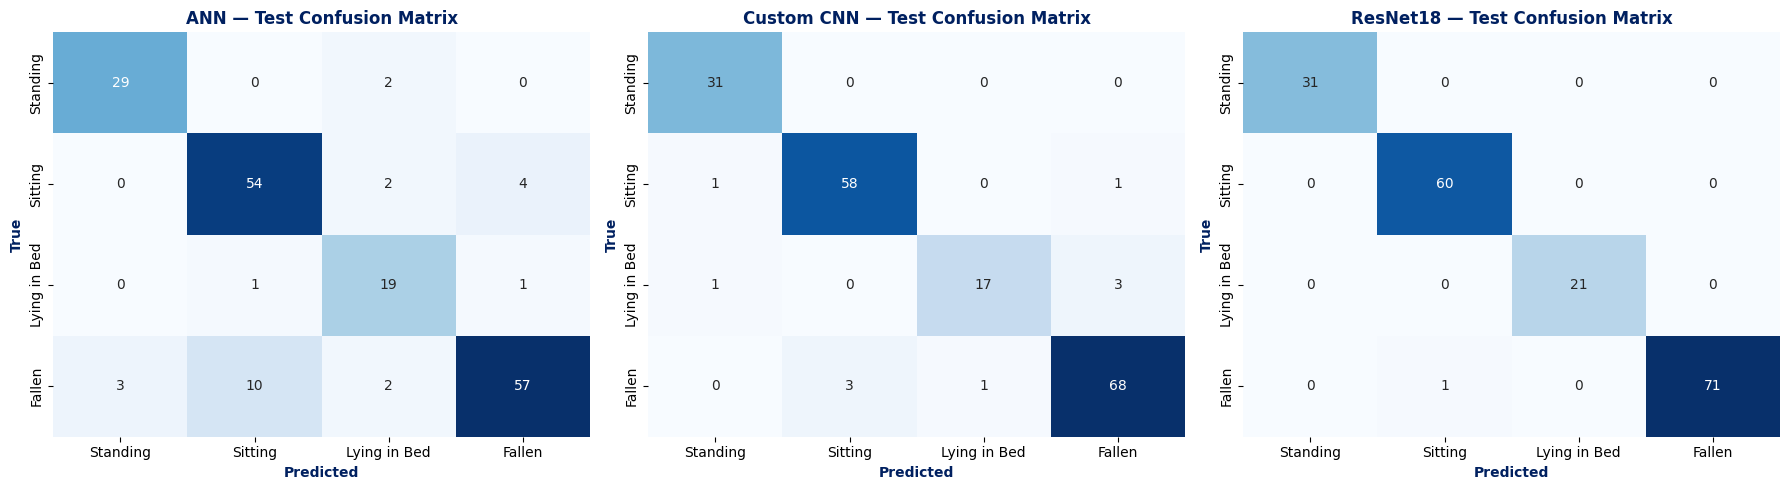

In [32]:
import seaborn as sns

fig, axs = plt.subplots(1, 3, figsize=(18, 5))
for ax, name in zip(axs, ["ANN", "Custom CNN", "ResNet18"]):
    y_true, y_pred, _ = test_predictions[name]
    sns.heatmap(confusion_matrix(y_true, y_pred), annot=True, fmt="d", cmap="Blues",
                cbar=False, xticklabels=class_names, yticklabels=class_names, ax=ax)
    ax.set_title(f"{name} — Test Confusion Matrix", weight="bold", color="#002060")
    ax.set_xlabel("Predicted", weight="bold", color="#002060")
    ax.set_ylabel("True", weight="bold", color="#002060")
plt.tight_layout()
plt.savefig("final_confusion_matrices.png", dpi=300, bbox_inches="tight")
plt.show()


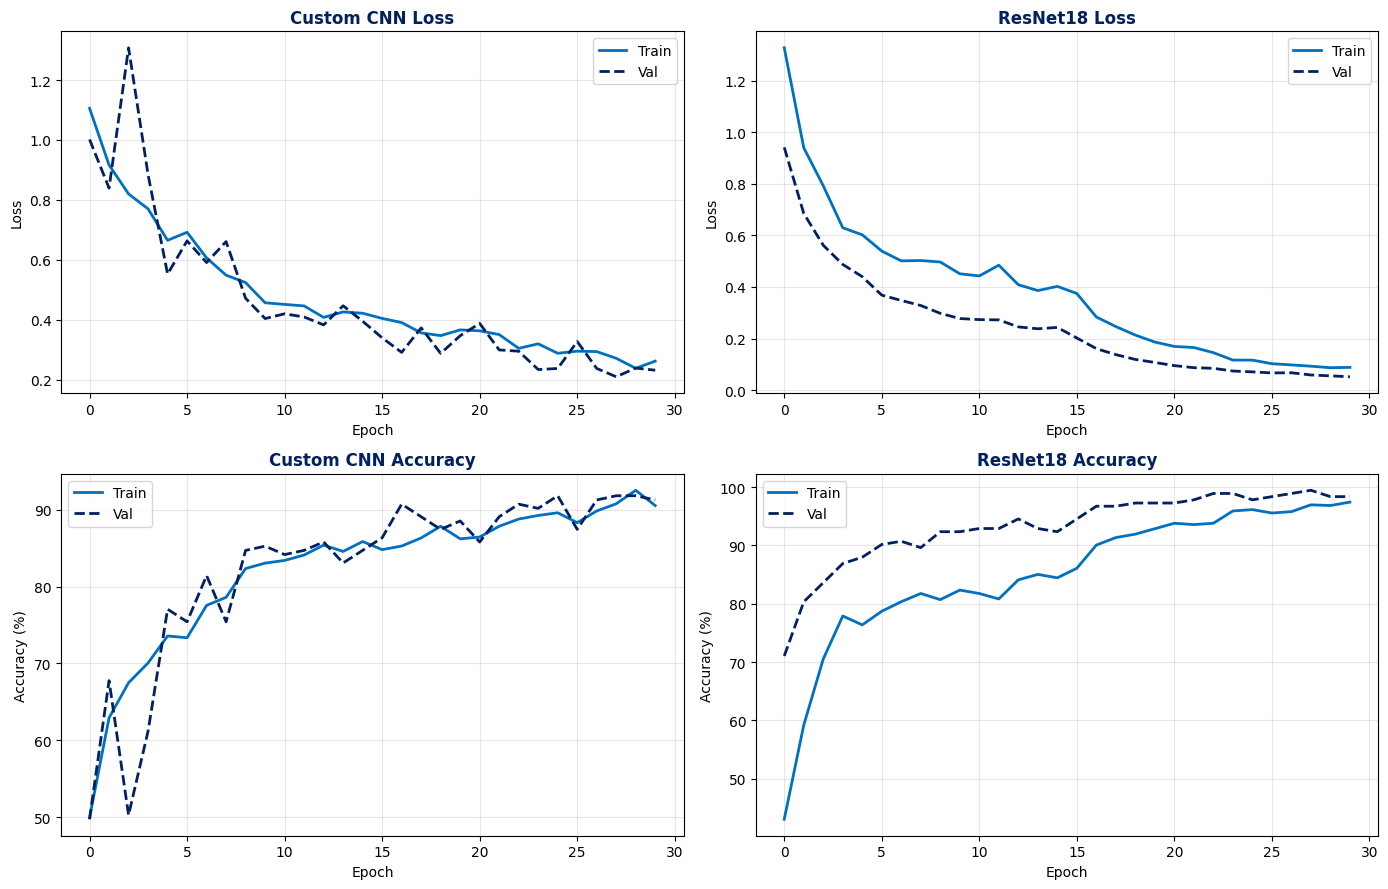

In [33]:
fig, axs = plt.subplots(2, 2, figsize=(14, 9))
for col, (title, hist) in enumerate([("Custom CNN", best_cnn_history),
                                     ("ResNet18", resnet_history)]):
    axs[0, col].plot(hist["train_loss"], label="Train", color="#0070C0", lw=2)
    axs[0, col].plot(hist["val_loss"], label="Val", color="#002060", lw=2, ls="--")
    axs[0, col].set_title(f"{title} Loss", weight="bold", color="#002060")
    axs[0, col].set_xlabel("Epoch"); axs[0, col].set_ylabel("Loss")
    axs[0, col].legend(); axs[0, col].grid(alpha=0.3)

    axs[1, col].plot([a * 100 for a in hist["train_acc"]], label="Train", color="#0070C0", lw=2)
    axs[1, col].plot([a * 100 for a in hist["val_acc"]], label="Val", color="#002060", lw=2, ls="--")
    axs[1, col].set_title(f"{title} Accuracy", weight="bold", color="#002060")
    axs[1, col].set_xlabel("Epoch"); axs[1, col].set_ylabel("Accuracy (%)")
    axs[1, col].legend(); axs[1, col].grid(alpha=0.3)
plt.tight_layout()
plt.show()


Qualitative predictions (ResNet18)

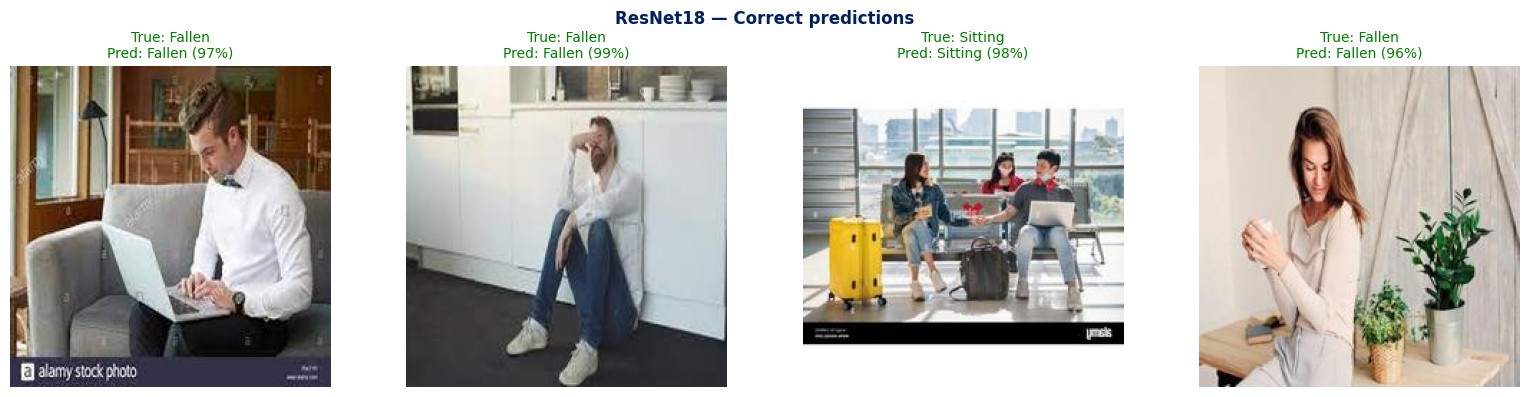

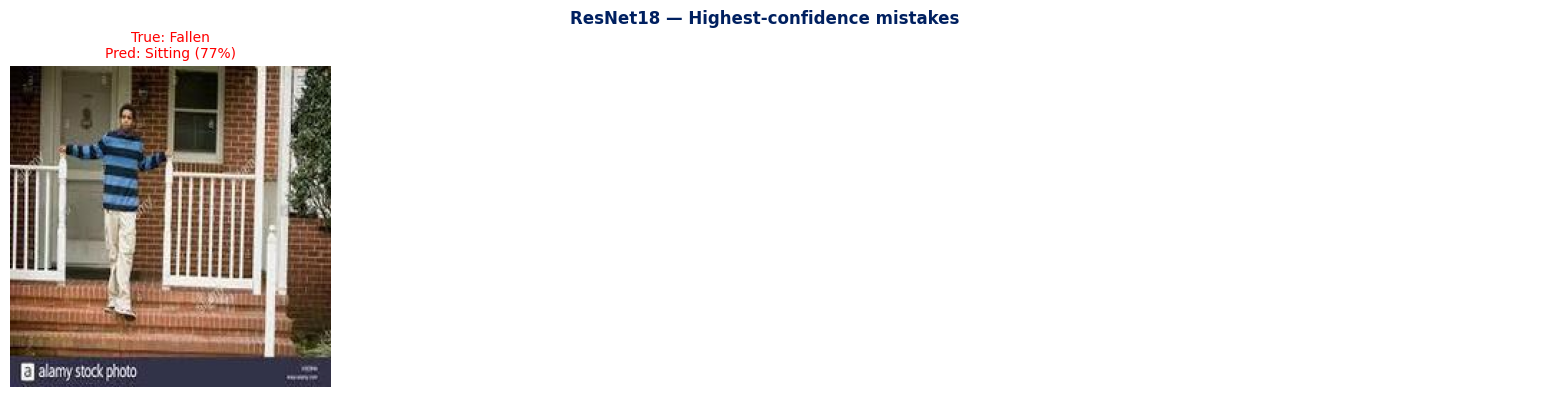

In [34]:
def denorm(t):
    mean = torch.tensor(norm_mean).view(3, 1, 1)
    std = torch.tensor(norm_std).view(3, 1, 1)
    return (t * std + mean).clamp(0, 1)

def show_prediction_grid(dataset, indices, y_pred, y_prob, title, cols=4):
    rows = int(np.ceil(len(indices) / cols))
    fig, axes = plt.subplots(rows, cols, figsize=(4 * cols, 4 * rows))
    axes = np.array(axes).reshape(-1)
    for ax, idx in zip(axes, indices):
        img, label = dataset[idx]
        pred = y_pred[idx]
        ax.imshow(denorm(img).permute(1, 2, 0).numpy())
        ax.set_title(f"True: {class_names[label]}\nPred: {class_names[pred]} "
                     f"({y_prob[idx, pred]:.0%})", fontsize=10,
                     color="green" if pred == label else "red")
        ax.axis("off")
    for ax in axes[len(indices):]:
        ax.axis("off")
    plt.suptitle(title, weight="bold", color="#002060")
    plt.tight_layout()
    plt.show()

y_true, y_pred, y_prob = test_predictions["ResNet18"]
correct = np.where(y_pred == y_true)[0]
wrong = np.where(y_pred != y_true)[0]
# Sort the mistakes by how confident the model was (most confident errors first).
hi_conf_wrong = wrong[np.argsort([y_prob[i, y_pred[i]] for i in wrong])[::-1]] if len(wrong) else wrong

show_prediction_grid(tf_test_ds, correct[:4], y_pred, y_prob, "ResNet18 — Correct predictions")
if len(wrong):
    show_prediction_grid(tf_test_ds, hi_conf_wrong[:4], y_pred, y_prob,
                         "ResNet18 — Highest-confidence mistakes")




Grad-CAM highlights the image regions that drove the prediction. For this task we want to see
whether the model looks at the person and the supporting surface (bed / floor) rather than
irrelevant background. This is a small hook-based implementation on ResNet18's `layer4`.

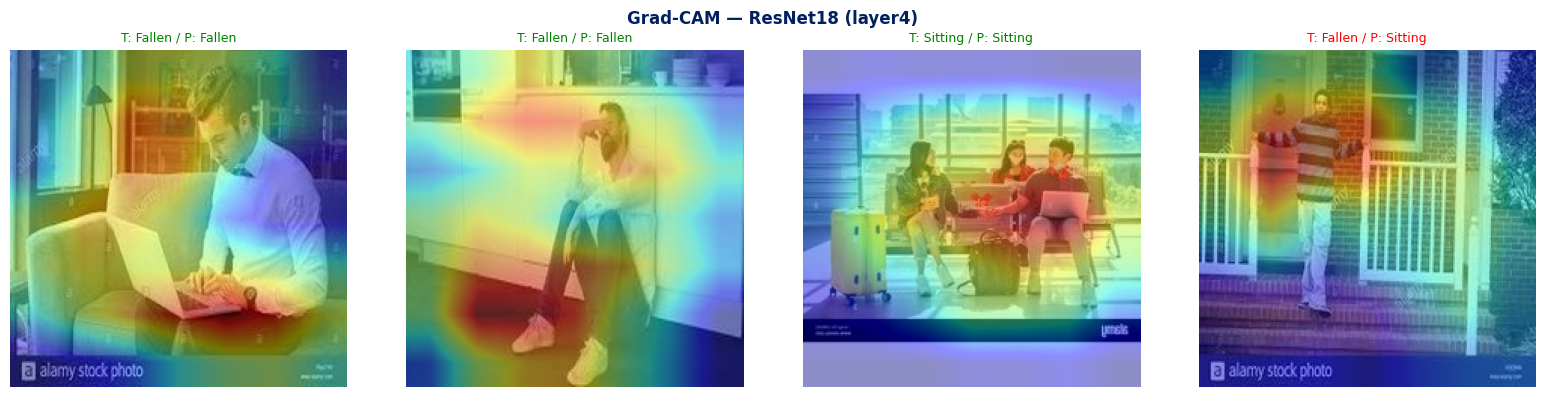

In [35]:
import torch.nn.functional as F

class GradCAM:
    """Grad-CAM via one forward hook (activations) and one backward hook (gradients)."""
    def __init__(self, model, target_layer):
        self.model = model
        self.activations = None
        self.gradients = None
        target_layer.register_forward_hook(self._save_activation)
        target_layer.register_full_backward_hook(self._save_gradient)

    def _save_activation(self, module, inp, out):
        self.activations = out.detach()

    def _save_gradient(self, module, grad_in, grad_out):
        self.gradients = grad_out[0].detach()

    def __call__(self, x, class_idx=None):
        self.model.eval()
        logits = self.model(x)
        if class_idx is None:
            class_idx = int(logits.argmax(1).item())
        self.model.zero_grad()
        logits[0, class_idx].backward()
        weights = self.gradients.mean(dim=(2, 3), keepdim=True)     # global-average-pool gradients
        cam = F.relu((weights * self.activations).sum(dim=1, keepdim=True))
        cam = F.interpolate(cam, size=x.shape[2:], mode="bilinear", align_corners=False)
        cam = cam.squeeze().cpu().numpy()
        cam = (cam - cam.min()) / (cam.max() - cam.min() + 1e-8)
        return cam

cam_engine = GradCAM(resnet, resnet.layer4[-1])

show_idx = list(correct[:3]) + (list(hi_conf_wrong[:1]) if len(wrong) else list(correct[3:4]))
fig, axes = plt.subplots(1, len(show_idx), figsize=(4 * len(show_idx), 4))
for ax, idx in zip(np.array(axes).reshape(-1), show_idx):
    img, label = tf_test_ds[idx]
    cam = cam_engine(img.unsqueeze(0).to(device), class_idx=int(y_pred[idx]))
    ax.imshow(denorm(img).permute(1, 2, 0).numpy())
    ax.imshow(cam, cmap="jet", alpha=0.45)
    ax.set_title(f"T: {class_names[label]} / P: {class_names[y_pred[idx]]}", fontsize=9,
                 color="green" if y_pred[idx] == label else "red")
    ax.axis("off")
plt.suptitle("Grad-CAM — ResNet18 (layer4)", weight="bold", color="#002060")
plt.tight_layout()
plt.show()


 Here the test images are edited with a
few mild transformations  to see how much accuracy and fall recall drop.

In [36]:
robust_conditions = {
    "Original": tf_eval_tf,
    "Low brightness": transforms.Compose([
        transforms.Resize((224, 224)), transforms.ColorJitter(brightness=(0.4, 0.4)),
        transforms.ToTensor(), transforms.Normalize(norm_mean, norm_std)]),
    "Mild blur": transforms.Compose([
        transforms.Resize((224, 224)), transforms.GaussianBlur(kernel_size=5, sigma=1.5),
        transforms.ToTensor(), transforms.Normalize(norm_mean, norm_std)]),
    "Slight rotation": transforms.Compose([
        transforms.Resize((224, 224)), transforms.RandomRotation((15, 15)),
        transforms.ToTensor(), transforms.Normalize(norm_mean, norm_std)]),
    "Partial crop": transforms.Compose([
        transforms.Resize((224, 224)), transforms.CenterCrop(160), transforms.Resize((224, 224)),
        transforms.ToTensor(), transforms.Normalize(norm_mean, norm_std)]),
}

robust_rows = []
for cond, tf_ in robust_conditions.items():
    loader = DataLoader(ElderSafeDataset(manifest_file, "test", transform=tf_),
                        batch_size=32, shuffle=False)
    yt, yp, _ = collect_predictions(resnet, loader)
    robust_rows.append({
        "Condition": cond,
        "Accuracy (%)": round(accuracy_score(yt, yp) * 100, 2),
        "Fall Recall": round(fall_metrics(yt, yp)["fall_recall"], 3),
    })

robust_df = pd.DataFrame(robust_rows)
print("ResNet18 robustness under simple input corruptions:")
print(robust_df.to_string(index=False))


ResNet18 robustness under simple input corruptions:
      Condition  Accuracy (%)  Fall Recall
       Original         99.46        0.986
 Low brightness         97.83        0.972
      Mild blur         97.28        0.958
Slight rotation         96.20        0.972
   Partial crop         95.65        1.000


## Staged test

The internal test set is drawn from the same public datasets used for training, so it mostly
measures *in-distribution* performance. As promised in the proposal, I also took my own staged
photos in a different room / camera / lighting and stored them under
`/content/drive/MyDrive/eldersafe/data/personaltest/`. Evaluating on these images is a much
harder domain shift test and gives a better picture of how ElderSafe would behave in a
new home.

The cell below matches the class sub-folders flexibly, so it works whether the floor class folder
is named `fallen`, `floor`, or `lying_on_floor`

In [43]:
%pip install -q pillow-heif

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.6/5.6 MB 69.7 MB/s eta 0:00:00


In [44]:
from pillow_heif import register_heif_opener

register_heif_opener()
print("HEIC support enabled.")

HEIC support enabled.


In [51]:
from pathlib import Path
from pillow_heif import register_heif_opener
import pandas as pd

# Allows PIL.Image.open() to read HEIC/HEIF files later.
register_heif_opener()

personal_dir = Path("/content/drive/MyDrive/eldersafe/data/personaltest")

image_ext = {
    ".jpg", ".jpeg", ".png", ".bmp", ".webp",
    ".heic", ".heif"
}

def match_label(folder_name):
    key = folder_name.lower().replace(" ", "").replace("-", "").replace("_", "")

    if "stand" in key:
        return 0
    if "sit" in key:
        return 1
    if "bed" in key or "couch" in key:
        return 2
    if "floor" in key or "fall" in key or "fallen" in key:
        return 3

    return None

records = []

if not personal_dir.exists():
    print(f"Folder not found: {personal_dir}")
    print("\nFolders available inside data:")

    data_dir = personal_dir.parent
    if data_dir.exists():
        for item in sorted(data_dir.iterdir()):
            print(" -", item.name)
    else:
        print(f"The parent folder also does not exist: {data_dir}")

else:
    print(f"Found folder: {personal_dir}\n")

    for sub in sorted(personal_dir.iterdir()):
        if not sub.is_dir():
            continue

        label = match_label(sub.name)

        if label is None:
            print(f"Skipping unrecognized folder: {sub.name}")
            continue

        imgs = [
            p for p in sub.rglob("*")
            if p.is_file() and p.suffix.lower() in image_ext
        ]

        print(
            f"{sub.name:20s} -> "
            f"{class_names[label]:14s} ({len(imgs)} images)"
        )

        for p in imgs:
            records.append({
                "cleaned_filepath": str(p),
                "label": label,
                "split": "personal"
            })

assert records, (
    "No personal images were found. Check the Google Drive path, "
    "class-folder names, and file extensions."
)

personal_df = pd.DataFrame(records)
personal_csv = str(personal_dir / "personal_manifest.csv")
personal_df.to_csv(personal_csv, index=False)

print("\nTotal personal images:", len(personal_df))
print(
    personal_df["label"]
    .map(lambda label: class_names[label])
    .value_counts()
)

print("\nManifest saved to:", personal_csv)

Found folder: /content/drive/MyDrive/eldersafe/data/personaltest

Lying_on_Bed         -> Lying in Bed   (3 images)
Lying_on_Floor       -> Fallen         (4 images)
Sitting              -> Sitting        (5 images)
Standing             -> Standing       (5 images)

Total personal images: 17
label
Standing        5
Sitting         5
Fallen          4
Lying in Bed    3
Name: count, dtype: int64

Manifest saved to: /content/drive/MyDrive/eldersafe/data/personaltest/personal_manifest.csv


In [52]:
# Evaluate ResNet18 (and, for comparison, the custom CNN) on the personal set.
personal_ld_224 = DataLoader(
    ElderSafeDataset(personal_csv, "personal", transform=tf_eval_tf),
    batch_size=16, shuffle=False)
personal_ld_128 = DataLoader(
    ElderSafeDataset(personal_csv, "personal", transform=cnn_eval_tf),
    batch_size=16, shuffle=False)

pt_true, pt_pred, pt_prob = collect_predictions(resnet, personal_ld_224)
summarize("ResNet18 on PERSONAL (staged) set", pt_true, pt_pred)
print("Fall metrics (ResNet18):", {k: round(v, 3) for k, v in fall_metrics(pt_true, pt_pred).items()})

cnn_pt_true, cnn_pt_pred, _ = collect_predictions(best_cnn, personal_ld_128)
print("\nCustom CNN accuracy on personal set:",
      round(accuracy_score(cnn_pt_true, cnn_pt_pred) * 100, 2), "%")

# Internal vs. personal comparison table for the report.
internal_true, internal_pred, _ = test_predictions["ResNet18"]
generalization_df = pd.DataFrame([
    {"Evaluation set": "Internal test", "Images": len(internal_true),
     "Accuracy (%)": round(accuracy_score(internal_true, internal_pred) * 100, 2),
     "Macro F1": round(f1_score(internal_true, internal_pred, average="macro"), 3),
     "Fall recall": round(fall_metrics(internal_true, internal_pred)["fall_recall"], 3)},
    {"Evaluation set": "Personal (staged)", "Images": len(pt_true),
     "Accuracy (%)": round(accuracy_score(pt_true, pt_pred) * 100, 2),
     "Macro F1": round(f1_score(pt_true, pt_pred, average="macro"), 3),
     "Fall recall": round(fall_metrics(pt_true, pt_pred)["fall_recall"], 3)},
])
print("\nGeneralization comparison (ResNet18):")
print(generalization_df.to_string(index=False))


=== ResNet18 on PERSONAL (staged) set ===
Accuracy: 23.53%  |  Macro F1: 0.1652  |  Weighted F1: 0.1387
              precision    recall  f1-score   support

    Standing     0.0000    0.0000    0.0000         5
     Sitting     0.0000    0.0000    0.0000         5
Lying in Bed     0.2500    0.3333    0.2857         3
      Fallen     0.2500    0.7500    0.3750         4

    accuracy                         0.2353        17
   macro avg     0.1250    0.2708    0.1652        17
weighted avg     0.1029    0.2353    0.1387        17

Fall metrics (ResNet18): {'fall_recall': np.float64(0.75), 'fall_precision': np.float64(0.25), 'false_negative_rate': np.float64(0.25), 'false_positive_rate': np.float64(0.692)}


/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))



Custom CNN accuracy on personal set: 23.53 %

Generalization comparison (ResNet18):
   Evaluation set  Images  Accuracy (%)  Macro F1  Fall recall
    Internal test     184         99.46     0.996        0.986
Personal (staged)      17         23.53     0.165        0.750


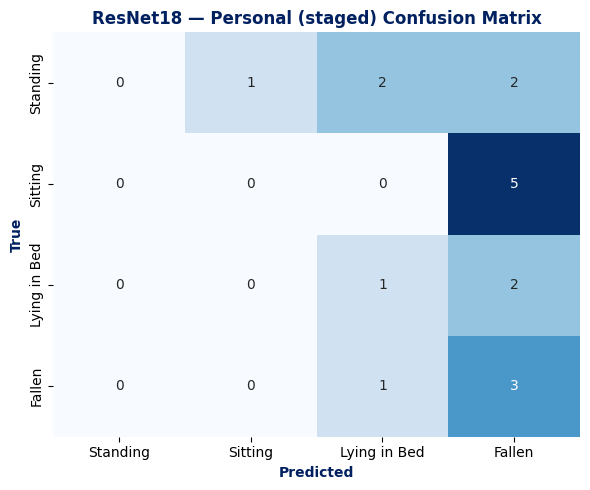

In [53]:
# Confusion matrix on the personal set.
fig, ax = plt.subplots(figsize=(6, 5))
sns.heatmap(confusion_matrix(pt_true, pt_pred, labels=[0, 1, 2, 3]), annot=True, fmt="d",
            cmap="Blues", cbar=False, xticklabels=class_names, yticklabels=class_names, ax=ax)
ax.set_title("ResNet18 — Personal (staged) Confusion Matrix", weight="bold", color="#002060")
ax.set_xlabel("Predicted", weight="bold", color="#002060")
ax.set_ylabel("True", weight="bold", color="#002060")
plt.tight_layout()
plt.savefig("personal_confusion_matrix.png", dpi=300, bbox_inches="tight")
plt.show()


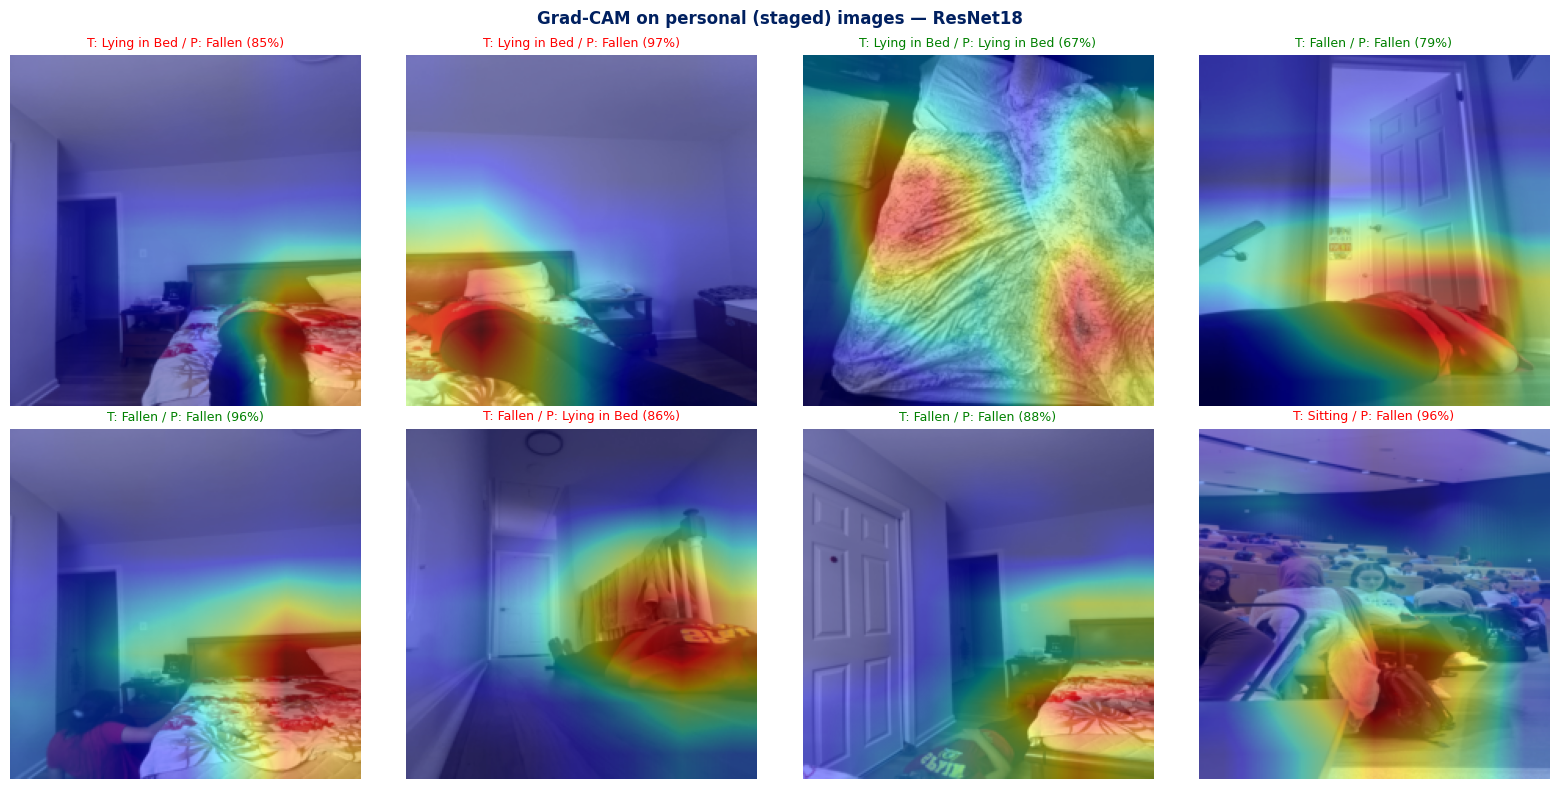

In [54]:
# Grad-CAM on the personal images: does the model look at the person / floor / bed,
# or at irrelevant background? This is the most informative part of the domain-shift check.
personal_ds_224 = ElderSafeDataset(personal_csv, "personal", transform=tf_eval_tf)
n_show = min(8, len(personal_ds_224))
cols = 4
rows = int(np.ceil(n_show / cols))
fig, axes = plt.subplots(rows, cols, figsize=(4 * cols, 4 * rows))
axes = np.array(axes).reshape(-1)
for ax, idx in zip(axes, range(n_show)):
    img, label = personal_ds_224[idx]
    cam = cam_engine(img.unsqueeze(0).to(device), class_idx=int(pt_pred[idx]))
    ax.imshow(denorm(img).permute(1, 2, 0).numpy())
    ax.imshow(cam, cmap="jet", alpha=0.45)
    ax.set_title(f"T: {class_names[label]} / P: {class_names[pt_pred[idx]]} "
                 f"({pt_prob[idx, pt_pred[idx]]:.0%})", fontsize=9,
                 color="green" if pt_pred[idx] == label else "red")
    ax.axis("off")
for ax in axes[n_show:]:
    ax.axis("off")
plt.suptitle("Grad-CAM on personal (staged) images — ResNet18", weight="bold", color="#002060")
plt.tight_layout()
plt.show()


 Save checkpoints and result tables

In [55]:
models_dir = "/content/drive/MyDrive/eldersafe/models"
os.makedirs(models_dir, exist_ok=True)

def save_checkpoint(model, path, input_size, best_epoch=None, val_loss=None):
    torch.save({
        "model_state_dict": model.state_dict(),
        "class_names": class_names,
        "input_size": input_size,
        "normalization_mean": norm_mean,
        "normalization_std": norm_std,
        "best_epoch": best_epoch,
        "validation_loss": val_loss,
        "random_seed": 42,
    }, path)
    print("Saved", path)

save_checkpoint(best_cnn, f"{models_dir}/eldersafe_cnn_final.pt", 128)
save_checkpoint(resnet, f"{models_dir}/eldersafe_resnet18_final.pt", 224,
                resnet_best_epoch, resnet_best_val)

cnn_experiment_df.to_csv(f"{models_dir}/cnn_experiments.csv", index=False)
final_table.to_csv(f"{models_dir}/final_model_comparison.csv", index=False)
robust_df.to_csv(f"{models_dir}/robustness_results.csv", index=False)
if "generalization_df" in dir():
    generalization_df.to_csv(f"{models_dir}/generalization_internal_vs_personal.csv", index=False)
print("\nAll checkpoints and result tables saved to Drive.")


Saved /content/drive/MyDrive/eldersafe/models/eldersafe_cnn_final.pt
Saved /content/drive/MyDrive/eldersafe/models/eldersafe_resnet18_final.pt

All checkpoints and result tables saved to Drive.


## Summary tables for the report

In [56]:
hyperparams = pd.DataFrame([
    {"Model": "ANN", "Input": "64x64", "Optimizer": "Adam", "LR": "0.001",
     "Batch": 32, "Weight decay": "-", "Epochs": "20"},
    {"Model": "Custom CNN", "Input": "128x128", "Optimizer": "AdamW", "LR": "1e-3 / 3e-4",
     "Batch": 32, "Weight decay": "1e-4", "Epochs": "<=30 (early stop)"},
    {"Model": "ResNet18", "Input": "224x224", "Optimizer": "AdamW", "LR": "1e-3 head / 1e-5 layer4",
     "Batch": 32, "Weight decay": "1e-4", "Epochs": "15 + 15"},
])
print("Hyperparameter settings:")
print(hyperparams.to_string(index=False))
print("\nFinal model comparison:")
print(final_table.to_string(index=False))
print("\nCNN experiment log:")
print(cnn_experiment_df.to_string(index=False))


Hyperparameter settings:
     Model   Input Optimizer                      LR  Batch Weight decay            Epochs
       ANN   64x64      Adam                   0.001     32            -                20
Custom CNN 128x128     AdamW             1e-3 / 3e-4     32         1e-4 <=30 (early stop)
  ResNet18 224x224     AdamW 1e-3 head / 1e-5 layer4     32         1e-4           15 + 15

Final model comparison:
     Model  Parameters  Test Accuracy (%)  Macro F1  Fall Recall  Fall FNR  Fall Precision
       ANN     3162692              86.41    0.8654       0.7917    0.2083          0.9194
Custom CNN      406084              94.57    0.9359       0.9444    0.0556          0.9444
  ResNet18    11178564              99.46    0.9962       0.9861    0.0139          1.0000

CNN experiment log:
model  learning_rate  dropout  class_weights  best_epoch  best_val_loss  val_accuracy  val_macro_f1
CNN-A         0.0010      0.4          False          28         0.2098        0.9180        0.9098
C